# Tratamiento de datos, pipeline de features y modelos 2 (no supervisado) y 3 (supervisado)
**Lookwise Data Lab** · Sistema de recomendación para clientes nuevos de H&M (e-commerce)
**Autor:** Lookwise Data Lab · **Fase:** Preparación de datos y modelado
**Continúa:** `03_baseline.ipynb` (baseline, métricas y Modelo 1 por edad)

---

## Objetivo
Llevar el sistema de recomendación desde la **línea base actual** (mostrar lo más vendido) hasta un **sistema personalizado** que funcione tanto para clientes nuevos como para clientes con historial, con cada decisión medida y justificada.

| Pregunta de negocio | Dónde se responde |
|---|---|
| ¿Los datos son confiables para tomar decisiones? | Sección 1 · tratamiento de datos cuantificado (`src/datos.py`) |
| ¿Qué información de clientes y productos usamos para recomendar? | Sección 2 · pipeline de características (`src/features.py`) |
| ¿Cuánto aporta aprovechar el historial de compras? | Sección 3 · Modelo 2, co-compra (no supervisado) |
| ¿Puede un modelo aprender a combinar todas las señales? | Sección 4 · Modelo 3, ranker (supervisado) |
| ¿Cuál es el mejor modelo y cuánto mejora frente a hoy? | Sección 5 · comparación y tablero de resultados |
| **¿Qué modelo ganó y por qué?** | **Sección 6 · ganador por tipo de cliente, con métricas y KPIs** |
| ¿Qué sistema conviene implementar y por qué? | Sección 7 · justificación y alternativas descartadas |
| ¿Qué debería hacer H&M? | Secciones 8 y 9 · resumen ejecutivo, conclusiones y recomendaciones |

## Hipótesis del estudio
Antes de ver los resultados del test definimos **qué esperamos encontrar** y **cómo lo vamos a verificar**. Así la conclusión no se acomoda a los números. El veredicto automático está en el **Paso 5.7**.

| # | Hipótesis | Por qué la planteamos (evidencia previa) | Cómo se verifica | Si se cumple, H&M puede… |
|---|---|---|---|---|
| **H1** | Personalizar por **edad** mejora la recomendación para **clientes nuevos** frente a "lo más vendido" | El EDA mostró que la edad cambia la mezcla de productos; es el único dato del cliente nuevo | M1 vs Baseline en **fríos** | Personalizar desde la primera visita |
| **H2** | Usar el **historial de compras** (co-compra) supera a personalizar solo por edad en clientes que ya compraron | El 89% de los clientes tiene más de una compra: hay señal que la edad no captura | M2 vs M1 en **con historial** | Ofrecer "Quienes compraron esto también compraron…" |
| **H3** | Un modelo **supervisado** que combina todas las señales supera al **no supervisado** | Cada modelo captura una señal distinta; aprender a combinarlas debería sumar | M3 vs M2 en **con historial** | Justificar la inversión en un modelo más complejo |
| **H4** | Lo **reciente** predice mejor que lo **histórico** (la moda cambia rápido) | El EDA mostró estacionalidad fuerte | Popularidad 7 días vs histórica en **validación** | Actualizar las recomendaciones cada semana |
| **H5** | Personalizar **reparte la visibilidad** del catálogo en más prendas | Recomendar lo más vendido muestra las mismas 12 a todos | Prendas distintas: mejor modelo vs Baseline | Dar salida a la cola larga y reducir quiebres de stock |

**Criterio de verificación (fijado antes de ver el test):** **se cumple** si el modelo mejora MAP@12 y Hit Rate@12 **y** la mejora en MAP@12 es robusta (intervalo de confianza que no incluye el 0) · **mejora pero no es concluyente** si mejora pero el intervalo incluye el 0 · **no se cumple** si no mejora.

## Cómo está organizado el código
La lógica vive en **scripts** (reutilizables por todo el equipo y por la futura app de Streamlit); este notebook **los usa y explica los resultados**.

| Script | Qué hace | Etapa CRISP-DM |
|---|---|---|
| `src/datos.py` | Carga, verificación y tratamiento de datos (cuantificado) | Entendimiento y preparación |
| `src/features.py` | Pipeline de features **sin leakage** | Preparación |
| `src/metricas.py` | Las 5 métricas del equipo + intervalo de confianza | Evaluación |
| `src/modelos.py` | Baseline, Modelo 1 (edad), Modelo 2 (co-compra, no supervisado) y Modelo 3 (ranker, supervisado), todos con la misma interfaz | Modelado |
| `src/pipeline.py` | Corre todo de punta a punta: `python src/pipeline.py --base <carpeta p10>` | Reproducibilidad |

> **Para reproducir:** cambiar `BASE` en la celda de configuración y ejecutar *Run All*.

> **Importante:** los resultados (tablas, gráficos y la **interpretación automática** de cada paso) aparecen **solo después de ejecutar Run All**. Cada celda de código imprime su propia interpretación con los números reales.

### Cómo leer este notebook
Cada paso tiene siempre la misma estructura:
1. **Paso X.Y:** qué vamos a hacer y por qué, en simple.
2. **Código:** lo que hace la computadora.
3. ** automática:** la interpretación que escribe el propio código con los resultados.
4. **Interpretación:** qué significa para el proyecto y para H&M.

---
## Configuración

**Qué hace esta celda:** prepara las herramientas antes de empezar.
- Trae las librerías (pandas, numpy, matplotlib).
- Trae **nuestros scripts** de `src/` (datos, features, métricas y modelos).
- Define dónde están los datos (`BASE`) y dónde se guardan los gráficos (`reports/figures`).
- Fija los colores y el estilo de todos los gráficos, para que se vean iguales en todo el proyecto.



In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("../src"))          # para importar los scripts de src/
from datos import cargar, verificar, tratar, separar, clientes_frios, CORTE_TEST
from features import construir_features, chequeo_sin_leakage
from metricas import compras_por_cliente, metricas, bootstrap_diferencia, tabla_bonita
from modelos import PopularidadReciente, PopularidadPorEdad, CoCompraRecompra, RankerSupervisado, modelo_final, ALGORITMOS
from sklearn.inspection import permutation_importance

BASE = "E:/Descargas_Henry/PF_HM/datos/p10"   # <- carpeta local de la muestra p10 (no se sube al repo)
FIG_DIR, OUT_DIR = "../reports/figures", "../reports"
os.makedirs(FIG_DIR, exist_ok=True)

AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#b4b3ad"
TEXTO, TEXTO2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")
def rotular(ax, barras, fmt):
    for b in barras:
        ax.annotate(fmt(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9, color=TEXTO)
print("Herramientas y scripts cargados . Datos desde:", BASE)

Herramientas y scripts cargados . Datos desde: E:/Descargas_Henry/PF_HM/datos/p10


---
# 1. Tratamiento de datos (cuantificado)

**Qué hacemos:** aplicamos las decisiones de la **tabla de decisiones del EDA** con `src/datos.py` y medimos **a cuántas filas o clientes afecta cada una**.

**Por qué:** una decisión sobre los datos solo es defendible si se sabe **a cuánto afecta**. Medir cada una garantiza un tratamiento sistemático, reproducible y que mantiene la integridad del dataset.

**Principio que seguimos:** **no borrar compras reales**. En un recomendador cada compra es una señal de preferencia; eliminar filas sin evidencia de error sesga lo que el modelo aprende.

### Paso 1.1 · Cargar y verificar los datos
**Qué hace:** lee las tres tablas de la muestra p10 (compras, clientes y artículos) y compara su tamaño con el que documentó el EDA del equipo.

**Por qué:** si mis datos fueran distintos a los del equipo, mis resultados no se podrían comparar con los de nadie.



In [2]:
trans, cust, art = cargar(BASE)
chequeo = verificar(trans, cust, art)
todo_ok = (chequeo["OK"] == "Sí").all()
print("", "los tamaños coinciden con el EDA del equipo: trabajamos todas con la misma base" if todo_ok
      else "los tamaños NO coinciden con el EDA: revisar que BASE apunte a la carpeta p10")
chequeo

Los tamaños coinciden con el EDA del equipo: trabajamos todas con la misma base


,Tabla,Esperado (EDA),Obtenido,OK
0,transactions,"(2226486, 5)","(2226486, 5)",
1,customers,"(110252, 7)","(110252, 7)",
2,articles,"(105542, 25)","(105542, 25)",


#### Hallazgo
Si los tres tamaños dan «Sí», la muestra p10 es **idéntica a la del EDA del equipo** (2.226.486 compras, 110.252 clientes y 105.542 artículos).

#### Implicancia para el negocio
Todos los resultados que siguen son **comparables con los del resto del equipo** y se pueden **reproducir**: cualquier persona que corra este notebook obtiene los mismos números. Para H&M significa que la recomendación se apoya en datos verificados, no en una copia distinta.

### Paso 1.2 · Aplicar las decisiones del equipo y medir su impacto
**Qué hace:** aplica cada decisión de la tabla del EDA (canal, duplicados, meses atípicos, precios, edad vacía, edades extremas, columnas que no usamos, descripciones vacías, categorías "Unknown") y **cuenta cuántas filas o clientes toca cada una**.

**Cómo leer la tabla:** cada fila es un problema de calidad. Muestra cuántos casos afecta (`Afectados`), qué porcentaje del total es (`% del total`), qué decidimos (`Decisión`) y por qué (`Por qué`).

In [3]:
filas_antes = len(trans)
trans, cust, art, impacto = tratar(trans, cust, art)
reales = impacto[impacto["Tema"] != "Variables de cliente"]
mayor = reales.loc[reales["% del total"].idxmax()]
print(f"Se conservaron {len(trans):,} de {filas_antes:,} compras (no se borró ninguna compra real del canal online).")
print(f"   El problema más grande es '{mayor['Tema']}' ({mayor['% del total']}% de los casos) → decisión: {mayor['Decisión']}.")
print(f"   {(reales['% del total'] < 5).sum()} de {len(reales)} problemas afectan a menos del 5%: la calidad general de los datos es buena.")
impacto

Se conservaron 2,226,486 de 2,226,486 compras (no se borró ninguna compra real del canal online).
   El problema más grande es 'Meses atípicos' (14.38% de los casos) → decisión: Se conservan en train.
   5 de 8 problemas afectan a menos del 5%: la calidad general de los datos es buena.


,Tema,Hallazgo,Afectados,% del total,Decisión,Por qué
0,Canal de venta,Filas fuera del canal online,0,0.00,Solo canal 2 (online),El sistema recomienda en e-commerce; la muestr...
1,Duplicados,"Misma prenda, mismo cliente, mismo día",284045,12.76,Se conservan,No hay evidencia de error (pueden ser varias u...
2,Meses atípicos,Compras de marzo a mayo 2020,320246,14.38,Se conservan en train,La evaluación no cae en ese período; quitarlos...
3,Precios extremos,Precios fuera del rango IQR,166798,7.49,No se eliminan,Son ventas reales; el precio no es la variable...
4,Edad vacía,Clientes sin edad,1208,1.10,No se imputa: grupo 'sin edad',Imputar asignaría gustos ajenos; afecta a ~1% ...
5,Edades extremas,Edad < 18 o > 90,717,0.65,Se conservan,Son valores posibles; quedan en los tramos <25...
6,Variables de cliente,"Columnas excluidas: FN, Active, club_member_st...",5,71.43,Solo se usa la edad,Son una foto de un único momento (riesgo de fu...
7,Descripción de artículo,detail_desc vacía,416,0.39,Se conserva vacía,Los modelos actuales no usan texto libre
8,Categoría 'Unknown',garment_group_name = 'Unknown',3873,3.67,Se trata como una categoría más,"Es una clasificación explícita, no un faltante..."


#### Hallazgo
La tabla muestra el tamaño de cada problema de calidad y la decisión tomada. La **** de arriba indica cuál es el más grande y cuántos afectan a menos del 5%.

#### Implicancia para el negocio
**No se borró ninguna compra real.** En un recomendador cada compra es una señal de gusto: borrar filas sin evidencia de error haría que el sistema "olvide" preferencias reales de los clientes. Las decisiones quedan documentadas en `reports/tratamiento_datos.csv` para el dashboard.

### Paso 1.3 · Gráfico: ¿qué tan grande es cada problema?
**Qué hace:** dibuja la tabla anterior como barras. **Barra más larga = más filas o clientes afectados.** Permite ver de un vistazo qué problemas son relevantes y cuáles son menores.

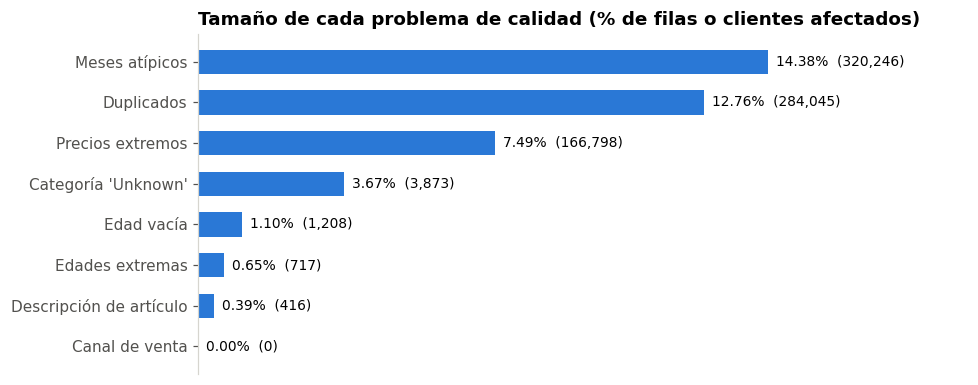

In [4]:
graf = impacto[impacto["Tema"] != "Variables de cliente"].sort_values("% del total")
fig, ax = plt.subplots(figsize=(9, 3.6))
barras = ax.barh(graf["Tema"], graf["% del total"], color=AZUL, height=0.6)
for b, n in zip(barras, graf["Afectados"]):
    ax.text(b.get_width() + 0.2, b.get_y() + b.get_height() / 2, f"{b.get_width():.2f}%  ({n:,})", va="center", fontsize=9)
ax.set_xlim(0, max(graf["% del total"].max() * 1.35, 1))
ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Tamaño de cada problema de calidad (% de filas o clientes afectados)")
fig.tight_layout(); guardar(fig, "08_tratamiento_datos"); plt.show()

#### Hallazgo
Las barras más largas son datos **válidos** que se conservan (meses atípicos, duplicados que pueden ser varias unidades). Los problemas reales de calidad (edad vacía, descripciones vacías) son **pequeños**.

#### Implicancia para el negocio
La base es **confiable para tomar decisiones**: los problemas de calidad no alcanzan para distorsionar las recomendaciones.

### Impacto de la decisión más discutida: ¿conservar o colapsar los duplicados?
El EDA encontró que ~12% de las filas repiten día, cliente y prenda. Medimos si cambia **lo que recomendaríamos**: comparamos el top 12 de la última semana con y sin duplicados.

In [5]:
train0, _ = separar(trans)
ult = train0[train0["t_dat"] >= CORTE_TEST - pd.Timedelta(days=7)]
top_con = ult["article_id"].value_counts().head(12).index
top_sin = ult.drop_duplicates(["t_dat", "customer_id", "article_id"])["article_id"].value_counts().head(12).index
coinciden = len(set(top_con) & set(top_sin))
print(f"Prendas del top 12 que coinciden con y sin duplicados: {coinciden} de 12")
print("", "conservar o colapsar los duplicados casi no cambia lo que recomendaríamos → conservarlos no altera el baseline"
      if coinciden >= 10 else "los duplicados SÍ cambian el top 12 → conviene comparar los modelos también con la versión colapsada")

Prendas del top 12 que coinciden con y sin duplicados: 11 de 12
Conservar o colapsar los duplicados casi no cambia lo que recomendaríamos → conservarlos no altera el baseline


### Interpretación
- **Ningún problema de calidad supera unos pocos puntos porcentuales**, salvo los duplicados (~12% de filas según el EDA) y los meses atípicos, que son **datos válidos** y se conservan.
- **Duplicados:** si el top 12 casi no cambia al colapsarlos, la decisión de conservarlos **no altera las recomendaciones** del baseline. Se conservan porque pueden ser varias unidades (talles para regalar, reposición), y eso es demanda real.
- **Edad vacía (~1,1%):** se agrupa como "sin edad" en vez de imputar; inventar una edad asignaría gustos ajenos.
- **Variables de cliente excluidas (5 de 7 columnas):** `FN`, `Active`, `club_member_status`, `fashion_news_frequency` y `postal_code` son **una foto tomada en un solo momento** (posiblemente después del período de test → *leakage*) y el EDA mostró que aportan poca señal.
- **Outliers de precio y edad:** no se eliminan; son valores posibles y el precio no es variable objetivo.

**Implicancia:** el dataset mantiene su integridad (no se borró ninguna compra real) y cada decisión queda **documentada y reproducible** en `src/datos.py` y exportada en `reports/tratamiento_datos.csv`.

---
# 2. Pipeline de ingeniería de características

**Qué hacemos:** con `src/features.py` construimos tres tablas de features **a una fecha de corte**:

| Tabla | Feature | Qué captura | Por qué sirve para recomendar |
|---|---|---|---|
| **Clientes** | `n_compras`, `n_articulos_distintos`, `dias_activos` | Cuánto y qué tan variado compra | Distingue clientes fríos, tibios y frecuentes (cada uno necesita otra estrategia) |
| **Clientes** | `dias_desde_ultima`, `dias_desde_primera` | Recencia y antigüedad | Un cliente que compró ayer tiene gustos "frescos" |
| **Clientes** | `compras_por_dia_activo`, `precio_medio` | Tamaño de canasta y nivel de gasto | Relaciona con el KPI de productos por pedido |
| **Clientes** | `pref_<grupo>` | % de sus compras en cada grupo (Ladieswear, Divided…) | Preferencia de estilo |
| **Clientes** | `tramo_edad`, `edad_faltante`, `es_frio` | Perfil disponible desde el registro | Única información para el cliente nuevo |
| **Artículos** | `ventas_7d`, `ventas_30d`, `ventas_total` | Popularidad en distintos plazos | Base de los modelos de popularidad |
| **Artículos** | `tendencia` | Ventas de esta semana vs la anterior | Detecta prendas que están "subiendo" (estacionalidad) |
| **Artículos** | `dias_desde_primera_venta`, `es_novedad` | Antigüedad en el catálogo | Las prendas nuevas son un techo para los modelos de historial (punto 7 del EDA) |
| **Artículos** | atributos (`product_type_name`, `colour_group_name`, …) | Qué es la prenda | Insumo del futuro modelo de contenido |
| **Co-compra** | `veces` por par de artículos | Cuántas veces se compraron juntos (mismo cliente, mismo día) | Base del **Modelo 2** |

| Decisión | Por qué sí | Por qué no la alternativa |
|---|---|---|
| **Calcular todo "a una fecha de corte"** | Garantiza que el modelo nunca vea el futuro (anti-*leakage*) | **Calcular con todo el dataset:** el test "se filtraría" en las features y el resultado sería falso |
| **Canasta = mismo cliente y mismo día** | Son prendas elegidas juntas: señal de complementariedad | **Todo el historial de 2 años como una canasta:** el EDA mostró que mezcla temporadas y genera ruido |
| **Funciones en un script** | Las reutiliza el notebook, el pipeline y la futura app | **Código suelto en el notebook:** no reproducible ni reutilizable |

### Paso 2.1 · Construir las features
**Qué hace:** corre el pipeline de `src/features.py` con fecha de corte 16/09/2020 y arma las tres tablas (clientes, artículos y co-compra). Después verifica automáticamente que **ninguna feature use compras del test**.



In [6]:
train, test = separar(trans)
frios = clientes_frios(trans)
feats = construir_features(trans, cust, art, hasta=CORTE_TEST)
for nombre, tabla in feats.items():
    print(f"{nombre:<10} {tabla.shape[0]:>9,} filas × {tabla.shape[1]} columnas")
sin_leak = chequeo_sin_leakage(trans, CORTE_TEST, feats)
print("Chequeo anti-leakage (ninguna feature usa compras del test):", "Sí" if sin_leak else "No")
fc0 = feats["clientes"]
print(f"Tengo {fc0.shape[1] - 1} características por cliente y {feats['articulos'].shape[1] - 1} por artículo, "
      f"más {len(feats['cocompra']):,} pares de prendas compradas juntas. "
      f"{'Ninguna usa información del futuro' if sin_leak else 'revisar fuga de información'}.")
print("   Abajo: las primeras 5 filas de la tabla de clientes (cada fila es un cliente, cada columna una feature).")
feats["clientes"].head()

clientes     110,252 filas × 17 columnas
articulos    105,542 filas × 17 columnas
cocompra     261,612 filas × 3 columnas
Chequeo anti-leakage (ninguna feature usa compras del test):
Tengo 16 características por cliente y 16 por artículo, más 261,612 pares de prendas compradas juntas. Ninguna usa información del futuro .
   Abajo: las primeras 5 filas de la tabla de clientes (cada fila es un cliente, cada columna una feature).


,customer_id,age,edad_faltante,tramo_edad,n_compras,n_articulos_distintos,dias_activos,dias_desde_ultima,dias_desde_primera,precio_medio,compras_por_dia_activo,pref_Baby/Children,pref_Divided,pref_Ladieswear,pref_Menswear,pref_Sport,es_frio
0,13c37e6332aa62e1440ac8aac588fa84217e24b6a9a19c...,27.0,False,25-34,120,106,31,2.0,671.0,0.036078,3.870968,0.000000,0.158333,0.833333,0.000000,0.008333,False
1,13c41969253d0d44ae2e5620fc059f51a4ca15a47250d8...,47.0,False,45-54,2,2,1,180.0,180.0,0.029644,2.000000,0.000000,0.500000,0.000000,0.000000,0.500000,False
2,13c48f7eb49cdf2cdf3a9e4c37a5f7666f77347a830e1d...,57.0,False,55+,131,109,33,68.0,718.0,0.037076,3.969697,0.007634,0.213740,0.740458,0.022901,0.015267,False
3,13c4a91a5653b917d29e00ed594b9df7e519307b46fcb4...,36.0,False,35-44,2,2,1,649.0,649.0,0.029644,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,False
4,13c4c0b608f73529f1d7d0be91ffac9311b0e6025820a5...,25.0,False,25-34,62,49,27,7.0,688.0,0.041290,2.296296,0.016129,0.112903,0.725806,0.145161,0.000000,False


### Paso 2.2 · Gráficos de las features
**Qué hace:** tres gráficos para entender a los clientes y al catálogo antes de modelar:
1. **Clientes por cantidad de compras** antes del corte (naranja = clientes fríos, sin compras).
2. **Cola larga:** cuánto de las ventas se concentra en pocos artículos.
3. **Artículos según su historial:** cuántos tienen ventas, cuántos son novedades y cuántos nunca se vendieron.

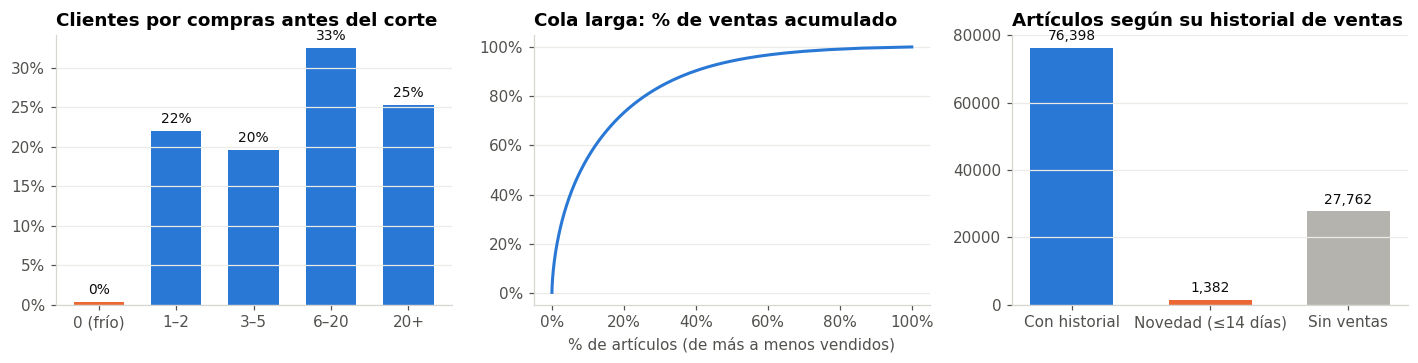

0.4% de los clientes no tenía compras antes del corte (fríos) y 25.3% compró más de 20 veces.
   El 20% de artículos más vendidos concentra el 73% de las ventas (cola larga).
   1,382 artículos son novedades y 27,762 nunca se vendieron: sin historial para co-compra.


In [7]:
fc, fa = feats["clientes"], feats["articulos"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
seg = pd.cut(fc["n_compras"], [-1, 0, 2, 5, 20, np.inf], labels=["0 (frío)", "1–2", "3–5", "6–20", "20+"]).value_counts().sort_index()
b = axes[0].bar(seg.index.astype(str), seg.values / seg.sum(), color=[NARANJA] + [AZUL] * 4, width=0.65)
rotular(axes[0], b, lambda v: f"{v:.0%}")
axes[0].set_title("Clientes por compras antes del corte"); axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
vend = fa[fa["ventas_total"] > 0]["ventas_total"].sort_values(ascending=False).to_numpy()
axes[1].plot(np.arange(1, len(vend) + 1) / len(vend), vend.cumsum() / vend.sum(), color=AZUL, lw=2)
axes[1].set_title("Cola larga: % de ventas acumulado"); axes[1].set_xlabel("% de artículos (de más a menos vendidos)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
nov = pd.Series({"Con historial": (~fa["es_novedad"] & ~fa["sin_ventas"]).sum(), "Novedad (≤14 días)": fa["es_novedad"].sum(), "Sin ventas": fa["sin_ventas"].sum()})
b = axes[2].bar(nov.index, nov.values, color=[AZUL, NARANJA, GRIS], width=0.6)
rotular(axes[2], b, lambda v: f"{v:,.0f}")
axes[2].set_title("Artículos según su historial de ventas")
fig.tight_layout(); guardar(fig, "09_features"); plt.show()
corte20 = max(1, int(len(vend) * 0.2))
print(f"{seg.iloc[0] / seg.sum():.1%} de los clientes no tenía compras antes del corte (fríos) y "
      f"{seg.iloc[-1] / seg.sum():.1%} compró más de 20 veces.")
print(f"   El 20% de artículos más vendidos concentra el {vend[:corte20].sum() / vend.sum():.0%} de las ventas (cola larga).")
print(f"   {int(fa['es_novedad'].sum()):,} artículos son novedades y {int(fa['sin_ventas'].sum()):,} nunca se vendieron: sin historial para co-compra.")

### Interpretación
- **Clientes por compras:** muestra cuántos clientes caen en cada etapa (frío, tibio, frecuente). Justifica un **sistema por etapas**: un solo modelo no sirve para todos.
- **Cola larga:** una curva que sube muy rápido indica que **pocos artículos concentran casi todas las ventas** y miles casi no se venden. Recomendar solo lo popular deja invisible la mayor parte del catálogo.
- **Novedades y artículos sin ventas:** son prendas sobre las que **no hay historial**; ningún modelo de co-compra puede recomendarlas. Es el techo del punto 7 del EDA y la razón para un futuro **modelo de contenido**.
- **Chequeo anti-leakage :** ninguna feature usa compras posteriores al corte.

**Implicancia:** las features traducen el comportamiento de clientes y productos a números que los modelos pueden usar, y alimentan al **ranker supervisado** de la sección 4, que las combinará.

---
# 3. Modelo 2 · No supervisado: co-compra + recompra (filtrado colaborativo ítem-ítem)

### La idea en simple (en lenguaje de negocio)
*El código de este modelo está más abajo, en los pasos . Este bloque explica la lógica en términos de negocio.*
> *"Quienes compraron esta prenda también compraron estas otras"* (co-compra) + *"volver a mostrar lo que ya te gustó"* (recompra).

Para cada cliente se toman sus **últimas 10 prendas**; se suman puntos a (a) las prendas que **otros clientes compraron junto con ellas** y (b) **las mismas prendas** (en moda se repite: otro color, otro talle, reposición de básicos). Lo comprado recientemente pesa más. Si no alcanza para 12, se completa con el **Modelo 1 (edad)**.

### ¿Por qué este modelo?
- **Aprende sin etiquetas (no supervisado):** la co-compra es **filtrado colaborativo item-item**; descubre qué prendas se compran juntas sin que nadie se lo indique.
- **El EDA mostró** que el 89% de los clientes tiene más de una compra: hay historial que la popularidad desperdicia.
- **Es explicable:** "te mostramos esto porque compraste aquello".

| Decisión | Por qué sí | Por qué no la alternativa |
|---|---|---|
| **Item-item (co-compra)** | Escala bien, es explicable y funciona con matrices muy dispersas (EDA: >80% de pares aparecen 1 vez) | **Factorización de matrices (ALS/SVD):** más costosa, menos explicable y no ayuda a clientes fríos; queda como mejora posible |
| **Pares de los últimos 14–28 días** (elegido en validación) | Refleja tendencias actuales | **Todo el historial:** mezcla temporadas (estacionalidad del EDA) |
| **Sumar recompra** (probado en validación, con y sin) | En moda se repite mucho la misma prenda | **Asumir sin probar:** se decide con datos en la semana de validación |
| **Respaldo con Modelo 1** | Cliente sin historial → igual recibe 12 recomendaciones personalizadas por edad | **Respaldo con top general:** desaprovecha la edad |
| **Últimas 10 prendas, más peso a lo reciente** | Los gustos cambian; lo de esta semana dice más que lo de hace un año | **Todas las compras con igual peso:** clientes antiguos quedarían "atados" a gustos viejos |

> **Limitación honesta:** para un cliente **realmente frío** (0 compras) este modelo **no tiene de dónde aprender** y usa el respaldo por edad. Su valor está en los clientes **con historial**, y en convertir rápido a un cliente nuevo en uno con historial tras su **primera compra**.

## 3.1 Elección de parámetros en validación
Probamos 4 combinaciones (ventana de pares 14 o 28 días × con o sin recompra) en la semana de validación (09–15/09), **sin tocar el test**. También se eligen allí las ventanas del baseline y del Modelo 1.

### Paso 3.2 · Probar configuraciones en la semana de validación
**Qué hace:**
1. Elige la mejor ventana del **baseline** (7, 14, 30 días o histórico).
2. Elige la mejor ventana del **Modelo 1** (7, 14 o 30 días).
3. Prueba 4 versiones del **Modelo 2** y se queda con la de mayor MAP@12.

Todo se mide en la semana del 09 al 15/09, **sin tocar el test**.



In [8]:
VAL = CORTE_TEST - pd.Timedelta(days=7)
val_c = compras_por_cliente(train[train["t_dat"] >= VAL])
tramo = cust.set_index("customer_id")["tramo_edad"].to_dict()

def elegir(candidatos):
    filas = []
    for m in candidatos:
        m.fit(train, VAL)
        filas.append({"Modelo": m.nombre, **metricas(val_c, m.recomendar), "_m": m})
    t = pd.DataFrame(filas)
    return t.loc[t["MAP@12"].idxmax(), "_m"], t.drop(columns="_m")

baseline, v_base = elegir([PopularidadReciente(d) for d in [7, 14, 30, None]])
modelo1, v_m1 = elegir([PopularidadPorEdad(tramo, d) for d in [7, 14, 30]])
modelo2, v_m2 = elegir([CoCompraRecompra(modelo1, dias_pares=d, peso_recompra=w) for d in [14, 28] for w in [0.0, 1.0]])
print("Elegidos en validación:\n ·", baseline.nombre, "\n ·", modelo1.nombre, "\n ·", modelo2.nombre)
mb, m2 = v_base["MAP@12"].max(), v_m2["MAP@12"].max()
print(f"En validación, el mejor Modelo 2 logra MAP@12 = {m2:.4f} frente a {mb:.4f} del mejor baseline "
      f"({'mejora' if m2 > mb else 'no mejora'} de {(m2 / mb - 1) if mb else float('nan'):+.0%}).")
print("   Abajo: las 4 versiones del Modelo 2 probadas (la de mayor MAP@12 es la elegida).")
tabla_bonita(v_m2)

Elegidos en validación:
 · Baseline: popularidad 7 días
 · Modelo 1: popularidad por edad (30 días)
 · Modelo 2: co-compra + recompra (28 días)
En validación, el mejor Modelo 2 logra MAP@12 = 0.0299 frente a 0.0073 del mejor baseline (mejora de +311%).
   Abajo: las 4 versiones del Modelo 2 probadas (la de mayor MAP@12 es la elegida).


,Modelo,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Modelo 2: co-compra (14 días),0.0184,5347,9.11,4.23,0.96
1,Modelo 2: co-compra + recompra (14 días),0.0297,10410,11.73,6.10,1.25
2,Modelo 2: co-compra (28 días),0.0195,6813,8.88,4.36,0.94
3,Modelo 2: co-compra + recompra (28 días),0.0299,10561,11.50,6.16,1.24


#### Hallazgo
La **** compara el mejor Modelo 2 con el mejor baseline **en la semana de validación**. Si la mejora es grande, aprovechar el historial de compras (co-compra) supera claramente a "lo más vendido".

#### Implicancia para el negocio
Confirma con datos que **lo que el cliente ya compró dice mucho de lo que comprará después**: es la base de bloques como *"Quienes compraron esto también compraron…"*.

### Paso 3.3 · Gráfico de la validación del Modelo 2
**Qué hace:** muestra las 4 versiones como barras. **La azul es la elegida.** Abajo calcula cuánto aporta sumar la **recompra** (volver a mostrar lo que el cliente ya compró).

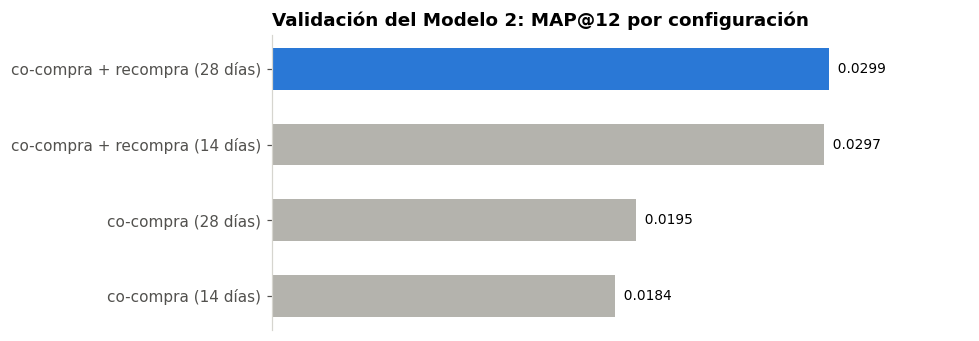

Aporte de la recompra en validación: MAP@12 0.0195 -> 0.0299 (+53%)


In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
v = v_m2.sort_values("MAP@12")
b = ax.barh(v["Modelo"].str.replace("Modelo 2: ", ""), v["MAP@12"],
            color=[AZUL if n == modelo2.nombre else GRIS for n in v["Modelo"]], height=0.55)
for barra in b:
    ax.text(barra.get_width(), barra.get_y() + barra.get_height() / 2, f"  {barra.get_width():.4f}", va="center", fontsize=9)
ax.set_xlim(0, v["MAP@12"].max() * 1.25); ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Validación del Modelo 2: MAP@12 por configuración")
fig.tight_layout(); guardar(fig, "10_validacion_modelo2"); plt.show()

con_r = v_m2[v_m2["Modelo"].str.contains("recompra")]["MAP@12"].max()
sin_r = v_m2[~v_m2["Modelo"].str.contains("recompra")]["MAP@12"].max()
print(f"Aporte de la recompra en validación: MAP@12 {sin_r:.4f} -> {con_r:.4f} ({(con_r / sin_r - 1) if sin_r else float('nan'):+.0%})")

### Interpretación
- La configuración en azul es la elegida (mayor MAP@12 en validación) y es la que se usa en el test.
- **Aporte de la recompra:** compara la mejor versión con y sin recompra. Si sube, confirma que en moda **volver a mostrar lo que el cliente ya eligió** es una señal valiosa (otro color, otro talle, básicos que se reponen). Si no sube, la co-compra sola alcanza y el modelo queda más simple.

**Implicancia:** la configuración se decide con evidencia, no por intuición, y el mismo procedimiento se aplica a todos los modelos.

---
# 4. Modelo 3 · Supervisado: ranker de candidatas ("aprender a ordenar")

### La idea en simple (en lenguaje de negocio)
*El código de este modelo está más abajo, en los pasos . Este bloque explica la lógica en términos de negocio.*
Los modelos anteriores siguen **reglas fijas** (contar ventas, contar co-compras). El Modelo 3 **aprende de los datos** qué señales predicen una compra:
1. **Candidatos:** junta las mejores 40 prendas de cada modelo anterior (popularidad, edad y co-compra).
2. **Pregunta que aprende a responder:** *"¿este cliente comprará esta prenda la próxima semana?"* (sí = 1, no = 0). Es un problema **supervisado de clasificación**.
3. **Ordena** los candidatos de cada cliente por probabilidad de compra y muestra los 12 primeros.

### ¿Con qué aprende? Features de cada par (cliente, prenda)
| Feature | Qué le dice al modelo |
|---|---|
| `rank_pop`, `rank_edad`, `rank_cocompra`, `puntaje_cocompra` | Qué tan arriba la puso cada modelo anterior (combina sus opiniones) |
| `ya_lo_compro` | Si es una recompra |
| `ventas_7d`, `ventas_30d`, `tendencia`, `dias_desde_primera_venta`, `precio_articulo` | Popularidad, si está subiendo y si es novedad |
| `ventas_tramo_7d`, `afinidad_grupo` | Si gusta en su tramo de edad y si coincide con el estilo que el cliente suele comprar |
| `age`, `edad_faltante`, `n_compras`, `dias_desde_ultima`, `compras_por_dia_activo` | Perfil y comportamiento del cliente (salen del pipeline de la sección 2) |

### Cómo se entrena sin hacer trampa
```
datos para features ──────────────┐  semana de etiquetas  │  se recomienda para
(todo lo anterior)                │  (¿compró o no?)      │
──────────────────────── 08/09 ──┼──── 09/09 → 15/09 ────┼──── 16/09 → 22/09 (TEST)
```
Las features usan solo datos **anteriores** a la semana de etiquetas, y el test nunca se usa para entrenar.

| Decisión | Por qué sí | Por qué no la alternativa |
|---|---|---|
| **Enfoque de candidatos + ranker** | Es el estándar de la industria en sistemas de recomendación: reduce 100.000 prendas a ~100 por cliente y después ordena con precisión | **Clasificar las 100.000 prendas por cliente:** inviable en tiempo y memoria |
| **Comparar 4 algoritmos y elegir en validación** (Paso 4.3) | Regresión logística, HistGradientBoosting, XGBoost y LightGBM se prueban con los mismos datos: se elige con evidencia | **Elegir un algoritmo "de moda" sin probar:** podría ser más complejo sin rendir mejor |
| **Etiquetas de la semana previa** | Imita exactamente la tarea real: predecir la semana siguiente | **Etiquetas de todo el historial:** mezcla temporadas y filtra el futuro |

### Paso 4.1 · Entrenar el Modelo 3 y medirlo en validación
**Qué hace:** entrena el ranker con las compras de la semana del 02 al 08/09 (aprende "¿compró o no?") y lo evalúa en la semana de validación, junto a los otros modelos. Puede tardar 1 o 2 minutos.

**Cómo leer la tabla:** está ordenada de mejor a peor por MAP@12. Arriba queda el modelo que mejor funcionó en el ensayo.

In [10]:
VAL = CORTE_TEST - pd.Timedelta(days=7)
modelo3_val = RankerSupervisado(tramo, cust, art, dias_pares=modelo2.dias_pares)
modelo3_val.fit(train, VAL, clientes=list(val_c))   # entrena con la semana 02-08/09 y predice la validación
v_m3 = pd.DataFrame([{"Modelo": modelo3_val.nombre, **metricas(val_c, modelo3_val.recomendar)}])
print(f"Filas de entrenamiento: {modelo3_val.filas_entrenamiento:,} pares (cliente, prenda) · "
      f"compras reales entre ellos: {modelo3_val.positivos_entrenamiento:,} "
      f"({modelo3_val.positivos_entrenamiento / modelo3_val.filas_entrenamiento:.2%})")
validacion = pd.concat([v_base, v_m1, v_m2, v_m3], ignore_index=True)
mejor_val = validacion.loc[validacion["MAP@12"].idxmax()]
print(f"En validación, el mejor de todos es '{mejor_val['Modelo']}' (MAP@12 = {mejor_val['MAP@12']:.4f}, "
      f"Hit Rate@12 = {mejor_val['Hit Rate@12']:.1%}: {mejor_val['Hit Rate@12'] * 100:.0f} de cada 100 clientes encontraron algo).")
tabla_bonita(validacion.sort_values("MAP@12", ascending=False))

Filas de entrenamiento: 399,548 pares (cliente, prenda) · compras reales entre ellos: 1,818 (0.46%)
En validación, el mejor de todos es 'Modelo 2: co-compra + recompra (28 días)' (MAP@12 = 0.0299, Hit Rate@12 = 11.5%: 12 de cada 100 clientes encontraron algo).


,Modelo,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
10,Modelo 2: co-compra + recompra (28 días),0.0299,10561,11.50,6.16,1.24
8,Modelo 2: co-compra + recompra (14 días),0.0297,10410,11.73,6.10,1.25
11,Modelo 3: ranker supervisado,0.0282,3939,13.80,6.39,1.39
9,Modelo 2: co-compra (28 días),0.0195,6813,8.88,4.36,0.94
7,Modelo 2: co-compra (14 días),0.0184,5347,9.11,4.23,0.96
6,Modelo 1: popularidad por edad (30 días),0.0080,47,6.29,2.39,0.58
4,Modelo 1: popularidad por edad (7 días),0.0074,59,5.79,1.98,0.52
0,Baseline: popularidad 7 días,0.0073,12,6.13,2.16,0.54
5,Modelo 1: popularidad por edad (14 días),0.0072,57,6.11,2.16,0.53
1,Baseline: popularidad 14 días,0.0059,12,6.04,2.13,0.52


#### Hallazgo
La tabla ordena **todos los modelos** de mejor a peor en el ensayo (validación). La fila de arriba es el ganador del ensayo. La proporción de compras reales entre los pares de entrenamiento es muy baja (~0,5%): por eso medimos con MAP@12 y no con accuracy.

#### Implicancia para el negocio
El modelo supervisado aprende **cómo combinar** todas las señales (historial, edad, tendencia, precio) en lugar de usar una sola regla. Si gana en validación, es el candidato a usar con los clientes que ya compraron.

### Paso 4.2 · ¿Qué aprendió el Modelo 3?
**Qué hace:** mide qué tan importante es cada señal: la "rompe" (la mezcla al azar) y mide cuánto empeora el modelo. **Si empeora mucho, esa señal era importante.**



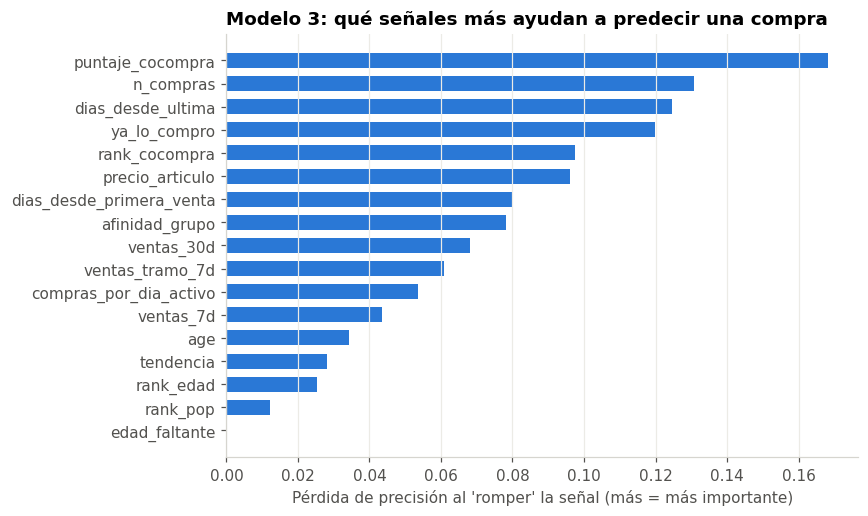

Las 5 señales que más ayudan a predecir una compra son:
   1. puntaje_cocompra: cuánto se compra junto con lo que el cliente ya compró
   2. n_compras: cuántas compras hizo el cliente
   3. dias_desde_ultima: hace cuántos días compró por última vez
   4. ya_lo_compro: si el cliente ya compró esa prenda (recompra)
   5. rank_cocompra: en qué puesto la puso el Modelo 2


In [11]:
# ¿Qué señales usa más el modelo? (importancia por permutación sobre una muestra del entrenamiento)
X, y = modelo3_val.X_entrenamiento, modelo3_val.y_entrenamiento
muestra = np.random.default_rng(42).choice(len(X), size=min(30000, len(X)), replace=False)
imp = permutation_importance(modelo3_val.clf, X.iloc[muestra], y[muestra], scoring="average_precision",
                             n_repeats=3, random_state=42)
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(importancia.index, importancia.values, color=[AZUL if v > 0 else GRIS for v in importancia.values], height=0.65)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Modelo 3: qué señales más ayudan a predecir una compra")
ax.set_xlabel("Pérdida de precisión al 'romper' la señal (más = más importante)")
fig.tight_layout(); guardar(fig, "12_importancia_modelo3"); plt.show()
explicacion = {"ya_lo_compro": "si el cliente ya compró esa prenda (recompra)",
               "puntaje_cocompra": "cuánto se compra junto con lo que el cliente ya compró",
               "rank_cocompra": "en qué puesto la puso el Modelo 2",
               "rank_pop": "en qué puesto la puso el baseline", "rank_edad": "en qué puesto la puso el Modelo 1",
               "afinidad_grupo": "si coincide con el estilo que el cliente suele comprar",
               "ventas_7d": "cuánto se vendió la última semana", "ventas_30d": "cuánto se vendió el último mes",
               "tendencia": "si las ventas de la prenda están subiendo",
               "dias_desde_primera_venta": "qué tan nueva es la prenda", "precio_articulo": "el precio de la prenda",
               "ventas_tramo_7d": "cuánto se vende entre gente de su edad", "age": "la edad del cliente",
               "edad_faltante": "si el cliente no informó su edad", "n_compras": "cuántas compras hizo el cliente",
               "dias_desde_ultima": "hace cuántos días compró por última vez",
               "compras_por_dia_activo": "cuántas prendas lleva por visita"}
print("Las 5 señales que más ayudan a predecir una compra son:")
for i, f in enumerate(importancia.sort_values(ascending=False).head(5).index, 1):
    print(f"   {i}. {f}: {explicacion.get(f, f)}")

### Interpretación
- **Filas de entrenamiento:** cada fila es un par (cliente, prenda candidata); muy pocas son compras reales (desbalance típico de recomendación). Por eso evaluamos con MAP@12 y no con accuracy: un modelo que dijera "no compra" siempre tendría >98% de accuracy y no serviría.
- **Importancia de señales:** muestra qué aprendió el modelo. Si arriba aparecen `ya_lo_compro`, `puntaje_cocompra` o `rank_cocompra`, confirma que **el historial del cliente** es la señal más valiosa; si aparecen `ventas_tramo_7d` o `tendencia`, la **edad y la temporada** también pesan. Se explica a la dirección en lenguaje de negocio: *"el sistema aprendió que lo que más predice una compra es…"*.

**Implicancia:** el modelo supervisado **combina** las fortalezas de los anteriores en vez de elegir uno solo, y su importancia de variables da **argumentos de negocio** (por ejemplo, invertir en recordatorios de recompra).

### Paso 4.3 · ¿Qué algoritmo conviene para el ranker? (Regresión logística vs HistGradientBoosting vs XGBoost vs LightGBM)
**Qué hace:** entrena el ranker con **cuatro algoritmos distintos**, usando **exactamente los mismos datos de entrenamiento y los mismos candidatos**. Así la única diferencia es el algoritmo. Los compara en la semana de validación y elige el de mayor MAP@12.

| Algoritmo | Tipo | Fortaleza | Debilidad |
|---|---|---|---|
| **Regresión logística** | Lineal | Muy explicable y rápida; sirve de referencia | Solo capta relaciones lineales; requiere imputar vacíos y escalar |
| **HistGradientBoosting** | Boosting de árboles (scikit-learn) | Relaciones no lineales; admite vacíos; sin librerías extra | Menos opciones de ajuste |
| **XGBoost** | Boosting de árboles | Referencia de la industria; muy preciso | Más lento; una librería más para mantener |
| **LightGBM** | Boosting de árboles | Muy rápido con muchos datos; preciso | Puede sobreajustar con pocos datos |

> Si XGBoost o LightGBM no están instalados, el paso los omite y lo avisa. Para instalarlos: `pip install xgboost lightgbm`.

,Segundos de entrenamiento,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
Algoritmo,,,,,,
Regresión logística,2.4,0.0323,10589,13.34,6.49,1.39
HistGradientBoosting,3.2,0.0282,3939,13.80,6.39,1.39
XGBoost,13.1,0.0310,3790,13.43,6.33,1.37
LightGBM,10.5,0.0297,3826,13.96,6.57,1.42


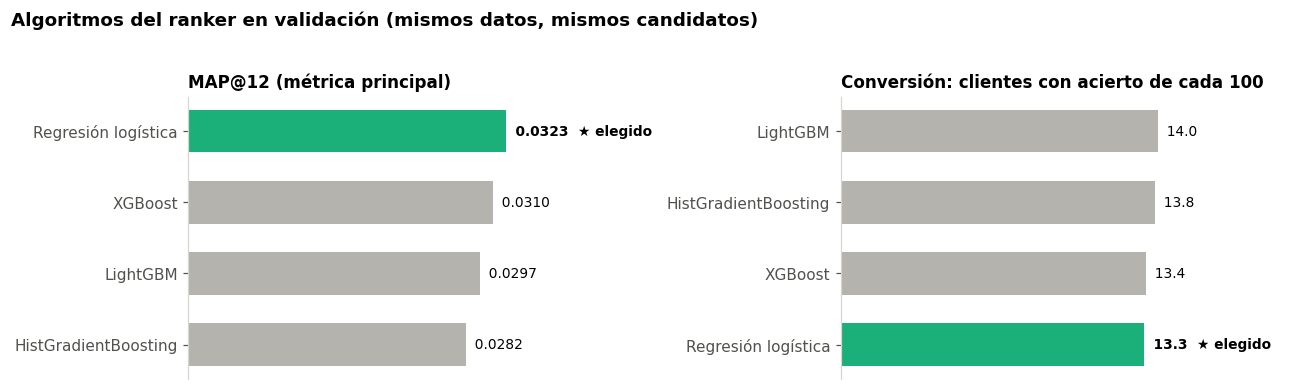

Gana Regresión logística con MAP@12 = 0.0323 (13.3 de cada 100 clientes con acierto), entrenando en 2.4 s.
   Diferencia entre el mejor y el peor algoritmo: +15% de MAP@12 (HistGradientBoosting).
   El ranker de las secciones 5 y 6 usa Regresión logística.


In [12]:
algoritmos, recs_alg = modelo3_val.comparar_algoritmos(val_c, evaluar=metricas)
MEJOR_ALG = algoritmos.loc[algoritmos["MAP@12"].idxmax(), "clave"]
display(tabla_bonita(algoritmos.drop(columns="clave")).set_index("Algoritmo"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, col, f, titulo in [(axes[0], "MAP@12", lambda x: f"{x:.4f}", "MAP@12 (métrica principal)"),
                           (axes[1], "Hit Rate@12", lambda x: f"{x * 100:.1f}", "Conversión: clientes con acierto de cada 100")]:
    orden = algoritmos.sort_values(col)
    vals = orden[col] * (100 if col == "Hit Rate@12" else 1)
    barras = ax.barh(orden["Algoritmo"], vals, color=[VERDE if k == MEJOR_ALG else GRIS for k in orden["clave"]], height=0.6)
    for b, k, x in zip(barras, orden["clave"], vals):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {f(x / (100 if col == 'Hit Rate@12' else 1))}" + ("  (elegido)" if k == MEJOR_ALG else ""),
                va="center", fontsize=9, fontweight="bold" if k == MEJOR_ALG else "normal")
    ax.set_xlim(0, vals.max() * 1.45); ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    ax.set_title(titulo, fontsize=11)
fig.suptitle("Algoritmos del ranker en validación (mismos datos, mismos candidatos)", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.03)
fig.tight_layout(); guardar(fig, "19_algoritmos_ranker"); plt.show()

mejor = algoritmos.set_index("clave").loc[MEJOR_ALG]
peor = algoritmos.loc[algoritmos["MAP@12"].idxmin()]
print(f"Gana {mejor['Algoritmo']} con MAP@12 = {mejor['MAP@12']:.4f} "
      f"({mejor['Hit Rate@12'] * 100:.1f} de cada 100 clientes con acierto), entrenando en {mejor['Segundos de entrenamiento']} s.")
print(f"   Diferencia entre el mejor y el peor algoritmo: {(mejor['MAP@12'] / peor['MAP@12'] - 1) * 100:+.0f}% de MAP@12 ({peor['Algoritmo']}).")
print(f"   El ranker de las secciones 5 y 6 usa {mejor['Algoritmo']}.")
_ = modelo3_val.usar_algoritmo(MEJOR_ALG)   # el ranker de validación pasa a usar el algoritmo elegido

#### Hallazgo
- Si los **algoritmos de árboles** (HistGradientBoosting, XGBoost, LightGBM) superan a la **regresión logística**, las señales se combinan de forma **no lineal** (por ejemplo, la recompra importa más en clientes frecuentes).
- Si las diferencias entre los de árboles son **pequeñas**, lo que más pesa es la **calidad de las features**, no el algoritmo. Es un resultado habitual en recomendación.
- Si gana la **regresión logística**, las señales construidas ya capturan casi toda la información: un modelo **lineal, más simple, rápido y explicable** alcanza, y no hace falta un algoritmo más complejo.
- La importancia de señales del Paso 4.2 se calculó con HistGradientBoosting; las señales principales suelen coincidir entre algoritmos de árboles.

#### Implicancia para el negocio
Se elige el algoritmo con **evidencia**, no por moda. Si el mejor es apenas superior a una alternativa más simple, conviene la simple: menos costo de mantenimiento y más fácil de explicar.

---
# 5. Comparación final de los cuatro modelos en el test

**Qué hacemos:** entrenamos los cuatro modelos con todo el train (hasta el 15/09) y los evaluamos en la semana de test (16–22/09) en **tres segmentos**:
- **Todos** los clientes que compraron en el test.
- **Con historial:** compraron al menos una vez antes del corte.
- **Fríos:** primera compra en la semana de test.

**Por qué por segmento:** cada modelo usa información distinta (nada, la edad, el historial), así que puede rendir distinto según el tipo de cliente. Un promedio general escondería esa diferencia, que es justamente la que justifica el diseño del sistema.

### Paso 5.1 · Entrenar los 4 modelos y medirlos en el test (el examen final)
**Qué hace:** vuelve a entrenar los 4 modelos con **todo** el train (hasta el 15/09) y los mide en la semana del 16 al 22/09, por segmento. Puede tardar 1 o 2 minutos.

**Cómo leer la tabla:** cada fila es un modelo en un segmento. Las columnas son las 5 métricas del equipo (los porcentajes ya están en %).

In [13]:
for m in [baseline, modelo1, modelo2]:
    m.fit(train, CORTE_TEST)
test_c = compras_por_cliente(test)
modelo3 = RankerSupervisado(tramo, cust, art, dias_pares=modelo2.dias_pares, algoritmo=MEJOR_ALG)
modelo3.nombre = f"Modelo 3: ranker supervisado ({ALGORITMOS[MEJOR_ALG]})"
modelo3.fit(train, CORTE_TEST, clientes=list(test_c))   # aprende con la semana 09-15/09

segmentos = {"Todos": test_c,
             "Con historial": {c: a for c, a in test_c.items() if c not in frios},
             "Fríos": {c: a for c, a in test_c.items() if c in frios}}
filas = [{"Modelo": m.nombre, "Grupo": g, "Clientes": len(comp), **metricas(comp, m.recomendar)}
         for m in [baseline, modelo1, modelo2, modelo3] for g, comp in segmentos.items()]
comparacion = pd.DataFrame(filas)
print(" (Hit Rate@12 = de cada 100 clientes, cuántos encontraron algo que compraron):")
for g in segmentos:
    sub = comparacion[comparacion["Grupo"] == g]
    top = sub.loc[sub["Hit Rate@12"].idxmax()]
    base_g = sub[sub["Modelo"] == baseline.nombre]["Hit Rate@12"].iloc[0]
    print(f"   {g:<14}: mejor = {top['Modelo']} → {top['Hit Rate@12'] * 100:.1f} de cada 100 "
          f"(baseline: {base_g * 100:.1f} de cada 100)")
tabla_bonita(comparacion)

 (Hit Rate@12 = de cada 100 clientes, cuántos encontraron algo que compraron):
   Todos         : mejor = Modelo 3: ranker supervisado (Regresión logística) → 12.8 de cada 100 (baseline: 7.0 de cada 100)
   Con historial : mejor = Modelo 3: ranker supervisado (Regresión logística) → 13.8 de cada 100 (baseline: 7.2 de cada 100)
   Fríos         : mejor = Baseline: popularidad 7 días → 4.6 de cada 100 (baseline: 4.6 de cada 100)


,Modelo,Grupo,Clientes,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Baseline: popularidad 7 días,Todos,4162,0.0083,12,6.97,2.71,0.65
1,Baseline: popularidad 7 días,Con historial,3725,0.0084,12,7.25,2.78,0.67
2,Baseline: popularidad 7 días,Fríos,437,0.0072,12,4.58,2.07,0.46
3,Modelo 1: popularidad por edad (30 días),Todos,4162,0.0056,54,5.43,2.06,0.48
4,Modelo 1: popularidad por edad (30 días),Con historial,3725,0.0055,54,5.56,2.08,0.49
5,Modelo 1: popularidad por edad (30 días),Fríos,437,0.0058,44,4.35,1.86,0.38
6,Modelo 2: co-compra + recompra (28 días),Todos,4162,0.0311,10247,10.88,6.00,1.14
7,Modelo 2: co-compra + recompra (28 días),Con historial,3725,0.0340,10247,11.65,6.49,1.22
8,Modelo 2: co-compra + recompra (28 días),Fríos,437,0.0058,44,4.35,1.86,0.38
9,Modelo 3: ranker supervisado (Regresión logíst...,Todos,4162,0.0332,9205,12.76,6.70,1.27


#### Hallazgo
Este es el **examen final**: la semana del 16 al 22/09, que ningún modelo vio. La **** dice, para cada segmento, cuántos clientes de cada 100 encontraron algo con el mejor modelo frente al baseline.

#### Implicancia para el negocio
Son los números **honestos** que se presentan a la dirección: miden lo que habría pasado si H&M hubiera usado cada sistema esa semana.

### Paso 5.2 · Tablero de comparación: ¿quién ganó cada métrica?
**Qué hace:** pone los 4 modelos **lado a lado**, una tabla por segmento de clientes:
- **Filas** = las 5 métricas del equipo · **Columnas** = los 4 modelos.
- (mejor) marca al **ganador** de cada métrica.
- **"Mejora vs baseline"** dice cuántas veces mejor (o peor) es el ganador frente a lo que H&M hace hoy.

Al final, un **medallero** cuenta cuántas métricas ganó cada modelo y un **veredicto** dice cuál gana en cada segmento.

#### Las 5 métricas: qué miden y por qué las usamos
| Métrica | Qué significa (en simple) | KPI de negocio | Por qué la usamos | Por qué no otra |
|---|---|---|---|---|
| **MAP@12** | ¿Acertamos **y** pusimos los aciertos arriba? | Experiencia | Es una **métrica estándar** para evaluar listas ordenadas de recomendaciones. Premia el orden, que importa porque en el celular se ven ~4 prendas | **Accuracy:** daría >99% diciendo "nadie compra nada" (solo ~0,5% de los pares son compras) |
| **Hit Rate@12** | De cada 100 clientes, ¿cuántos compraron algo de la lista? | **Conversión** (KPI principal) | Se traduce directo a negocio: "X de cada 100 clientes encontraron algo" | **Conversión real:** necesita visitas sin compra y un A/B en vivo, que no tenemos |
| **Recall@12** | ¿Qué parte de lo que el cliente compró anticipamos? | **Productos por pedido** (KPI secundario) | Si anticipamos más de su compra, es más fácil sumar prendas al carrito. Es el indicador estándar de cobertura en recomendación | **RMSE / MAE:** miden errores de un número (por ejemplo, un rating), no una lista |
| **Precision@12** | ¿Qué parte de los 12 lugares se aprovechó? | Uso de la vitrina | Cada lugar en pantalla es espacio de venta. Es el indicador estándar de aprovechamiento en recomendación | **AUC:** evalúa todo el catálogo, no las 12 que el cliente realmente ve |
| **Prendas distintas** | ¿A cuántas prendas les damos visibilidad? | Salud del catálogo | Detecta si mostramos siempre lo mismo (riesgo de quiebre de stock y cola larga invisible) | **Solo métricas de acierto:** no muestran el costo de concentrar todo en 12 prendas |



In [14]:
METRICAS = ["MAP@12", "Hit Rate@12", "Recall@12", "Precision@12", "Prendas distintas"]
PCT = {"Hit Rate@12", "Recall@12", "Precision@12"}
corto = {baseline.nombre: "Baseline", modelo1.nombre: "M1 · Edad",
         modelo2.nombre: "M2 · Co-compra (no sup.)", modelo3.nombre: "M3 · Ranker (sup.)"}

def formato(metrica, v):
    if metrica in PCT:
        return f"{v * 100:.2f}%"
    return f"{v:.4f}" if metrica == "MAP@12" else f"{int(v):,}"

medallero = {n: 0 for n in corto.values()}
veredicto = {}
for g in segmentos:
    sub = comparacion[comparacion["Grupo"] == g].set_index("Modelo")[METRICAS].rename(index=corto)
    filas = []
    for met in METRICAS:
        serie = sub[met]
        gan = serie.idxmax()
        medallero[gan] += 1
        base_v = serie["Baseline"]
        mejora = (f"x{serie[gan] / base_v:.1f}" if base_v else "—") if gan != "Baseline" else "= hoy"
        fila = {m: formato(met, v) + (" (mejor)" if m == gan else "") for m, v in serie.items()}
        filas.append({"Métrica": met, **fila, "Ganador": gan, "Mejora vs baseline": mejora})
    veredicto[g] = sub["MAP@12"].idxmax()
    print(f"\n━━━ Segmento: {g} ({len(segmentos[g]):,} clientes) ━━━  Ganador por MAP@12: {veredicto[g]}")
    display(pd.DataFrame(filas).set_index("Métrica"))

print("\nMétricas ganadas por modelo (3 segmentos, 15 posibles):")
for n, v in sorted(medallero.items(), key=lambda x: -x[1]):
    print(f"   {n:<26} {v}")
print("\nVEREDICTO:")
for g, gan in veredicto.items():
    print(f"   {g:<14} → gana {gan}")


━━━ Segmento: Todos (4,162 clientes) ━━━  Ganador por MAP@12: M3 · Ranker (sup.)


,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,Mejora vs baseline
Métrica,,,,,,
MAP@12,0.0083,0.0056,0.0311,0.0332,M3 · Ranker (sup.),x4.0
Hit Rate@12,6.97%,5.43%,10.88%,12.76%,M3 · Ranker (sup.),x1.8
Recall@12,2.71%,2.06%,6.00%,6.70%,M3 · Ranker (sup.),x2.5
Precision@12,0.65%,0.48%,1.14%,1.27%,M3 · Ranker (sup.),x2.0
Prendas distintas,12,54,"10,247","9,205",M2 · Co-compra (no sup.),x853.9



━━━ Segmento: Con historial (3,725 clientes) ━━━  Ganador por MAP@12: M3 · Ranker (sup.)


,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,Mejora vs baseline
Métrica,,,,,,
MAP@12,0.0084,0.0055,0.0340,0.0364,M3 · Ranker (sup.),x4.3
Hit Rate@12,7.25%,5.56%,11.65%,13.83%,M3 · Ranker (sup.),x1.9
Recall@12,2.78%,2.08%,6.49%,7.30%,M3 · Ranker (sup.),x2.6
Precision@12,0.67%,0.49%,1.22%,1.38%,M3 · Ranker (sup.),x2.1
Prendas distintas,12,54,"10,247","9,205",M2 · Co-compra (no sup.),x853.9



━━━ Segmento: Fríos (437 clientes) ━━━  Ganador por MAP@12: Baseline


,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,Mejora vs baseline
Métrica,,,,,,
MAP@12,0.0072,0.0058,0.0058,0.0056,Baseline,= hoy
Hit Rate@12,4.58%,4.35%,4.35%,3.66%,Baseline,= hoy
Recall@12,2.07%,1.86%,1.86%,1.60%,Baseline,= hoy
Precision@12,0.46%,0.38%,0.38%,0.31%,Baseline,= hoy
Prendas distintas,12,44,44,20,M1 · Edad,x3.7



Métricas ganadas por modelo (3 segmentos, 15 posibles):
   M3 · Ranker (sup.)          8
   Baseline                    4
   M2 · Co-compra (no sup.)    2
   M1 · Edad                   1

VEREDICTO:
   Todos          → gana M3 · Ranker (sup.)
   Con historial  → gana M3 · Ranker (sup.)
   Fríos          → gana Baseline


### Cómo leer el tablero
- **Marca (mejor):** el mejor valor de cada métrica. Si el mismo modelo gana MAP@12, Hit Rate y Recall, es **claramente superior** en ese segmento.
- **Mejora vs baseline:** "x3,0" significa **3 veces mejor** que lo que H&M hace hoy. Es el indicador más claro para la dirección.
- **Si un modelo gana MAP@12 pero pierde en "Prendas distintas"**, acierta mejor pero muestra menos variedad: es un *trade-off* que conviene mencionar.
- **En "Fríos" los Modelos 2 y 3 pueden empatar con el 1:** sin historial usan la edad como respaldo. Es coherente con el diseño, no un error.

**Implicancia para H&M:** el tablero justifica con números **qué modelo usar para cada tipo de cliente** (sistema por etapas) y cuánto mejora la experiencia frente a la estrategia actual.

### Paso 5.3 · ¿Cuánto mejora cada modelo frente al baseline? (incremento)
**Qué hace:** toma el **baseline como punto de partida (lo que H&M hace hoy)** y mide cuánto **suma** cada modelo:
1. **Escalera de mejora:** cómo sube el Hit Rate@12 al pasar de Baseline → M1 → M2 → M3 en cada segmento.
2. **Veces mejor que el baseline** en cada métrica ("x3" = 3 veces mejor).
3. **Tabla de incrementos** en lenguaje de negocio: **clientes de cada 100** que se suman frente a hoy.



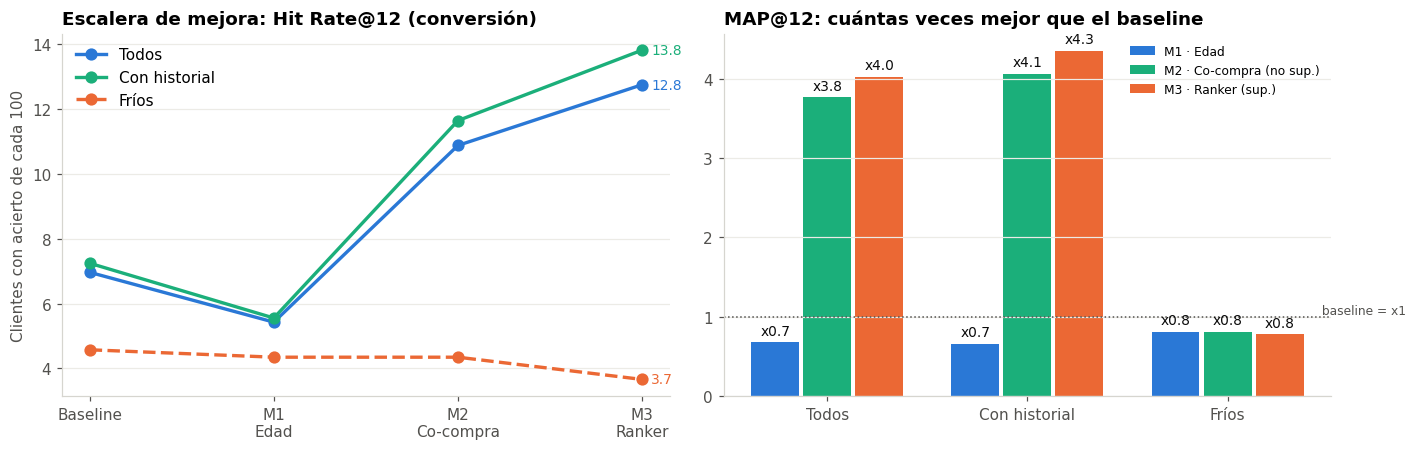

 (incremento frente a lo que H&M hace hoy):
   Todos         : con M3 · Ranker (sup.), 7.0 → 12.8 clientes de cada 100 (+5.8 frente al baseline).
   Con historial : con M3 · Ranker (sup.), 7.2 → 13.8 clientes de cada 100 (+6.6 frente al baseline).
   Fríos         : ningún modelo supera al baseline en Hit Rate.


,Segmento,Modelo,Clientes con acierto de cada 100,+ clientes de cada 100,MAP@12 vs baseline,Hit Rate@12 vs baseline,Recall@12 vs baseline,Precision@12 vs baseline
0,Todos,M1 · Edad,7.0 → 5.4,-1.5,-33%,-22%,-24%,-26%
1,Todos,M2 · Co-compra (no sup.),7.0 → 10.9,+3.9,+276%,+56%,+122%,+74%
2,Todos,M3 · Ranker (sup.),7.0 → 12.8,+5.8,+302%,+83%,+148%,+95%
3,Con historial,M1 · Edad,7.2 → 5.6,-1.7,-34%,-23%,-25%,-27%
4,Con historial,M2 · Co-compra (no sup.),7.2 → 11.7,+4.4,+306%,+61%,+133%,+82%
5,Con historial,M3 · Ranker (sup.),7.2 → 13.8,+6.6,+335%,+91%,+163%,+105%
6,Fríos,M1 · Edad,4.6 → 4.3,-0.2,-19%,-5%,-10%,-17%
7,Fríos,M2 · Co-compra (no sup.),4.6 → 4.3,-0.2,-19%,-5%,-10%,-17%
8,Fríos,M3 · Ranker (sup.),4.6 → 3.7,-0.9,-23%,-20%,-23%,-33%


In [15]:
MET_ACIERTO = ["MAP@12", "Hit Rate@12", "Recall@12", "Precision@12"]
orden_corto = ["Baseline", "M1 · Edad", "M2 · Co-compra (no sup.)", "M3 · Ranker (sup.)"]
col_m = {"Baseline": GRIS, "M1 · Edad": AZUL, "M2 · Co-compra (no sup.)": VERDE, "M3 · Ranker (sup.)": NARANJA}
comp_c = comparacion.assign(Modelo=comparacion["Modelo"].map(corto))

# --- Gráfico 1: escalera de Hit Rate@12 por segmento
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
estilo = {"Todos": ("-", AZUL), "Con historial": ("-", VERDE), "Fríos": ("--", NARANJA)}
for g, (ls, colr) in estilo.items():
    y = [comp_c[(comp_c["Modelo"] == m) & (comp_c["Grupo"] == g)]["Hit Rate@12"].iloc[0] * 100 for m in orden_corto]
    ax.plot(range(4), y, ls, color=colr, lw=2.2, marker="o", ms=7, label=g)
    ax.annotate(f"{y[-1]:.1f}", (3, y[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=colr)
ax.set_xticks(range(4), ["Baseline", "M1\nEdad", "M2\nCo-compra", "M3\nRanker"])
ax.set_ylabel("Clientes con acierto de cada 100")
ax.set_title("Escalera de mejora: Hit Rate@12 (conversión)")
ax.legend(loc="upper left")

# --- Gráfico 2: veces mejor que el baseline (MAP@12) por segmento
ax = axes[1]
grupos_l = list(segmentos); xs = np.arange(len(grupos_l)); w = 0.26
for j, m in enumerate(orden_corto[1:]):
    vals = []
    for g in grupos_l:
        b = comp_c[(comp_c["Modelo"] == "Baseline") & (comp_c["Grupo"] == g)]["MAP@12"].iloc[0]
        v = comp_c[(comp_c["Modelo"] == m) & (comp_c["Grupo"] == g)]["MAP@12"].iloc[0]
        vals.append(v / b if b else np.nan)
    barras = ax.bar(xs + (j - 1) * w, vals, w * 0.92, color=col_m[m], label=m)
    rotular(ax, barras, lambda v: f"x{v:.1f}")
ax.axhline(1, color=TEXTO2, lw=1, ls=":")
ax.text(xs[-1] + 0.45, 1, " baseline = x1", va="bottom", fontsize=8, color=TEXTO2)
ax.set_xticks(xs, grupos_l); ax.set_title("MAP@12: cuántas veces mejor que el baseline")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); guardar(fig, "13_incremento_vs_baseline"); plt.show()

# --- Tabla de incrementos
filas = []
for g in grupos_l:
    base = comp_c[(comp_c["Modelo"] == "Baseline") & (comp_c["Grupo"] == g)].iloc[0]
    for m in orden_corto[1:]:
        r = comp_c[(comp_c["Modelo"] == m) & (comp_c["Grupo"] == g)].iloc[0]
        fila = {"Segmento": g, "Modelo": m,
                "Clientes con acierto de cada 100": f"{base['Hit Rate@12'] * 100:.1f} → {r['Hit Rate@12'] * 100:.1f}",
                "+ clientes de cada 100": f"{(r['Hit Rate@12'] - base['Hit Rate@12']) * 100:+.1f}"}
        for met in MET_ACIERTO:
            fila[f"{met} vs baseline"] = f"{(r[met] / base[met] - 1) * 100:+.0f}%" if base[met] else "—"
        filas.append(fila)
incrementos = pd.DataFrame(filas)

print(" (incremento frente a lo que H&M hace hoy):")
for g in grupos_l:
    sub = incrementos[incrementos["Segmento"] == g]
    mejor = comp_c[comp_c["Grupo"] == g].set_index("Modelo")["Hit Rate@12"].idxmax()
    fila_m = sub[sub["Modelo"] == mejor]
    if len(fila_m):
        print(f"   {g:<14}: con {mejor}, {fila_m['Clientes con acierto de cada 100'].iloc[0]} clientes de cada 100 "
              f"({fila_m['+ clientes de cada 100'].iloc[0]} frente al baseline).")
    else:
        print(f"   {g:<14}: ningún modelo supera al baseline en Hit Rate.")
incrementos

### Cómo leer el incremento
- **Escalera (izquierda):** si la línea **sube en cada escalón**, cada modelo suma valor sobre el anterior. Donde la línea **se aplana**, el modelo más complejo ya no aporta y conviene el más simple (más barato y explicable).
- **Veces mejor (derecha):** la línea punteada es el baseline (x1). Una barra en **x2** significa el **doble** de calidad de ranking que hoy.
- **Tabla:** la columna **"+ clientes de cada 100"** resume el impacto en una frase: *"con nuestro sistema, X clientes más de cada 100 encuentran algo que compran"*.
- **En fríos**, se espera que la escalera se aplane después de M1: sin historial, los modelos 2 y 3 no tienen de qué aprender más. Por eso el diseño **por etapas**.

**Implicancia para H&M:** el incremento frente al baseline es **la base del cálculo de retorno de la inversión**. Cada cliente extra de cada 100 que compra es ingreso adicional, que se compara con el costo de la nube y del mantenimiento.

### Paso 5.4 · Duelo entre todos los modelos (baseline, M1, M2 y M3)
**Qué hace:** enfrenta a **todos los modelos de a pares**, incluido el baseline (lo que H&M hace hoy), para responder: *¿cuánto aporta cada modelo frente a hoy y frente a los demás?*
1. **Tabla de duelos:** 6 enfrentamientos, métrica por métrica y segmento por segmento, con la diferencia y el ganador.
2. **Gráfico de perfiles:** en cada segmento, cada métrica se expresa como **% del mejor modelo** (el mejor = 100%). Así se comparan métricas de escalas distintas en un mismo gráfico.
3. **Mapa de calor:** cuánto mejora (verde) o empeora (rojo) cada duelo en cada métrica.

| Duelo | Pregunta de negocio que responde |
|---|---|
| **M1 vs Baseline** | ¿Personalizar por edad mejora lo que H&M hace hoy? |
| **M2 vs Baseline** | ¿Aprovechar el historial mejora lo que H&M hace hoy? |
| **M3 vs Baseline** | ¿El modelo más completo mejora lo que H&M hace hoy? |
| **M2 vs M1** | ¿Aprovechar el historial (co-compra) supera a personalizar solo por edad? |
| **M3 vs M2** | ¿Vale la pena un modelo supervisado, más complejo, frente al no supervisado? |
| **M3 vs M1** | ¿El modelo más completo supera al más simple personalizado? |



Tabla de duelos (% = cuánto mejor o peor es el primero frente al segundo):


,Duelo,Segmento,MAP@12,Hit Rate@12,Recall@12,Precision@12,Ganador,Métricas ganadas
0,M1 vs Base,Todos,-33%,-22%,-24%,-26%,Base,M1 0 – 4 Base
1,M1 vs Base,Con historial,-34%,-23%,-25%,-27%,Base,M1 0 – 4 Base
2,M1 vs Base,Fríos,-19%,-5%,-10%,-17%,Base,M1 0 – 4 Base
3,M2 vs Base,Todos,+276%,+56%,+122%,+74%,M2,M2 4 – 0 Base
4,M2 vs Base,Con historial,+306%,+61%,+133%,+82%,M2,M2 4 – 0 Base
5,M2 vs Base,Fríos,-19%,-5%,-10%,-17%,Base,M2 0 – 4 Base
6,M3 vs Base,Todos,+302%,+83%,+148%,+95%,M3,M3 4 – 0 Base
7,M3 vs Base,Con historial,+335%,+91%,+163%,+105%,M3,M3 4 – 0 Base
8,M3 vs Base,Fríos,-23%,-20%,-23%,-33%,Base,M3 0 – 4 Base
9,M2 vs M1,Todos,+458%,+100%,+192%,+137%,M2,M2 4 – 0 M1


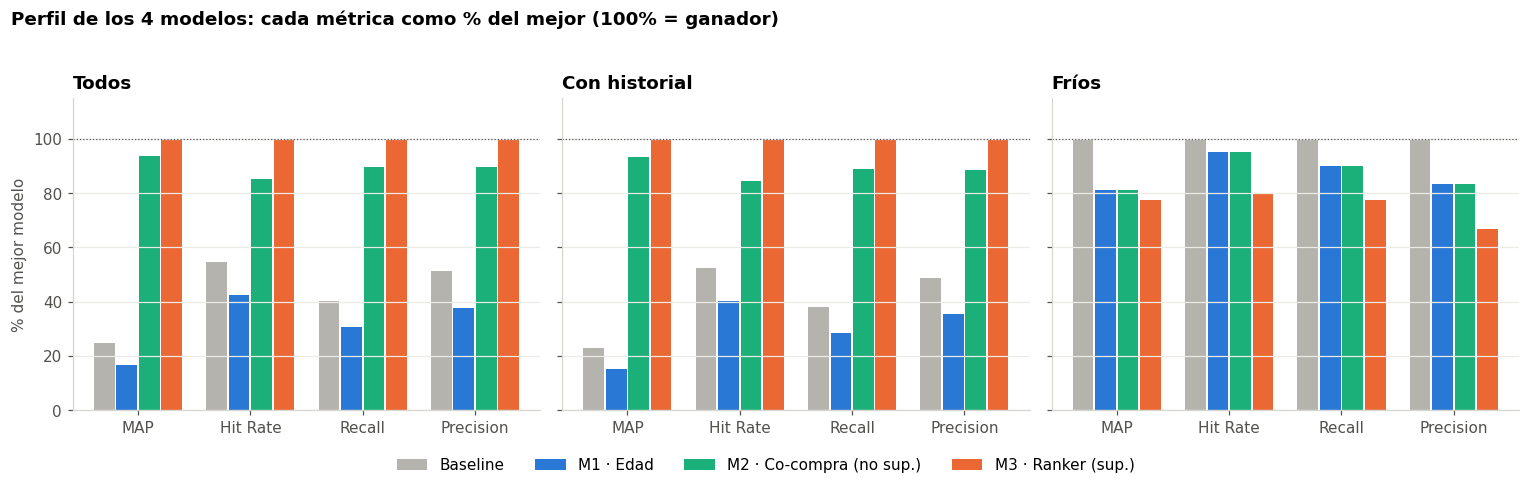

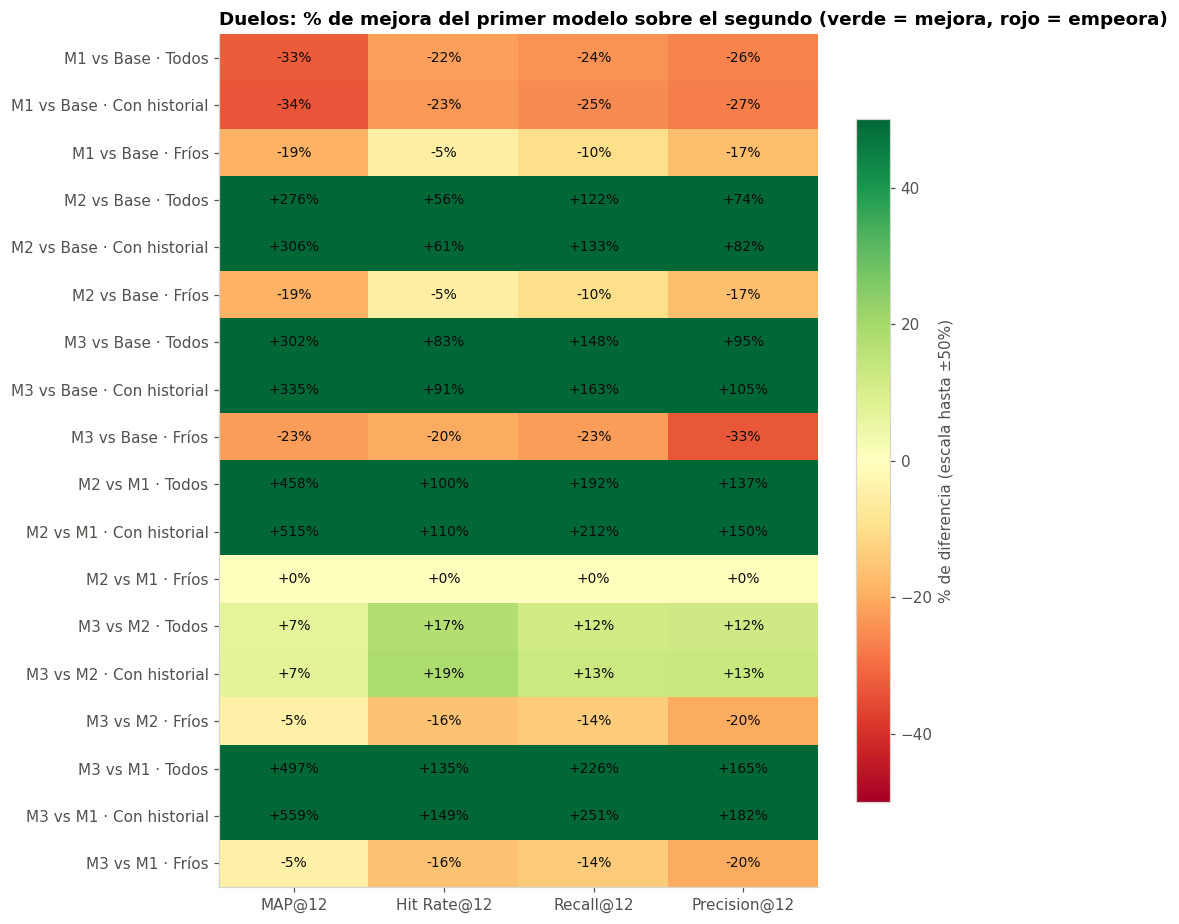

 de los duelos (por MAP@12, la métrica principal):
   M1 vs Base · Todos        : gana Base (MAP@12 -33%; métricas M1 0 – 4 Base)
   M1 vs Base · Con historial: gana Base (MAP@12 -34%; métricas M1 0 – 4 Base)
   M1 vs Base · Fríos        : gana Base (MAP@12 -19%; métricas M1 0 – 4 Base)
   M2 vs Base · Todos        : gana M2   (MAP@12 +276%; métricas M2 4 – 0 Base)
   M2 vs Base · Con historial: gana M2   (MAP@12 +306%; métricas M2 4 – 0 Base)
   M2 vs Base · Fríos        : gana Base (MAP@12 -19%; métricas M2 0 – 4 Base)
   M3 vs Base · Todos        : gana M3   (MAP@12 +302%; métricas M3 4 – 0 Base)
   M3 vs Base · Con historial: gana M3   (MAP@12 +335%; métricas M3 4 – 0 Base)
   M3 vs Base · Fríos        : gana Base (MAP@12 -23%; métricas M3 0 – 4 Base)
   M2 vs M1 · Todos        : gana M2   (MAP@12 +458%; métricas M2 4 – 0 M1)
   M2 vs M1 · Con historial: gana M2   (MAP@12 +515%; métricas M2 4 – 0 M1)
   M2 vs M1 · Fríos        : empate    (MAP@12 +0%; métricas M2 0 – 0 M1 (4 empate

In [16]:
TRES = ["Baseline", "M1 · Edad", "M2 · Co-compra (no sup.)", "M3 · Ranker (sup.)"]   # los 4 modelos
DUELOS = [("M1 · Edad", "Baseline"), ("M2 · Co-compra (no sup.)", "Baseline"), ("M3 · Ranker (sup.)", "Baseline"),
          ("M2 · Co-compra (no sup.)", "M1 · Edad"), ("M3 · Ranker (sup.)", "M2 · Co-compra (no sup.)"),
          ("M3 · Ranker (sup.)", "M1 · Edad")]
abrev = {"Baseline": "Base", "M1 · Edad": "M1", "M2 · Co-compra (no sup.)": "M2", "M3 · Ranker (sup.)": "M3"}

def v(m, g, met):
    return comp_c[(comp_c["Modelo"] == m) & (comp_c["Grupo"] == g)][met].iloc[0]

# --- 1. Tabla de duelos
filas = []
for a, b in DUELOS:
    for g in segmentos:
        fila = {"Duelo": f"{abrev[a]} vs {abrev[b]}", "Segmento": g}
        gana_a = gana_b = 0
        for met in MET_ACIERTO:
            va, vb = v(a, g, met), v(b, g, met)
            fila[met] = f"{(va / vb - 1) * 100:+.0f}%" if vb else "—"
            gana_a += va > vb; gana_b += vb > va
        fila["Ganador"] = abrev[a] if v(a, g, "MAP@12") > v(b, g, "MAP@12") else (
            "Empate" if v(a, g, "MAP@12") == v(b, g, "MAP@12") else abrev[b])
        empates = len(MET_ACIERTO) - gana_a - gana_b
        fila["Métricas ganadas"] = f"{abrev[a]} {gana_a} – {gana_b} {abrev[b]}" + (f" ({empates} empates)" if empates else "")
        filas.append(fila)
duelos = pd.DataFrame(filas)
print("Tabla de duelos (% = cuánto mejor o peor es el primero frente al segundo):")
display(duelos)

# --- 2. Perfiles: % del mejor modelo en cada métrica
fig, axes = plt.subplots(1, len(segmentos), figsize=(14, 3.9), sharey=True)
xs = np.arange(len(MET_ACIERTO)); w = 0.2
for ax, g in zip(axes, segmentos):
    for j, m in enumerate(TRES):
        vals = []
        for met in MET_ACIERTO:
            mejor = max(v(x, g, met) for x in TRES)
            vals.append(v(m, g, met) / mejor * 100 if mejor else 0)
        barras = ax.bar(xs + (j - 1.5) * w, vals, w * 0.92, color=col_m[m], label=m)
    ax.set_xticks(xs, ["MAP", "Hit Rate", "Recall", "Precision"]); ax.set_ylim(0, 115)
    ax.set_title(f"{g}"); ax.axhline(100, color=TEXTO2, lw=0.8, ls=":")
axes[0].set_ylabel("% del mejor modelo")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Perfil de los 4 modelos: cada métrica como % del mejor (100% = ganador)", x=0.01, ha="left",
             fontweight="bold", fontsize=12, y=1.03)
fig.tight_layout(); guardar(fig, "14_duelo_tres_modelos"); plt.show()

# --- 3. Mapa de calor de los duelos
matriz = pd.DataFrame(
    [[(v(a, g, met) / v(b, g, met) - 1) * 100 if v(b, g, met) else 0 for met in MET_ACIERTO]
     for a, b in DUELOS for g in segmentos],
    index=[f"{abrev[a]} vs {abrev[b]} · {g}" for a, b in DUELOS for g in segmentos],
    columns=["MAP@12", "Hit Rate@12", "Recall@12", "Precision@12"])
lim = 50   # escala de color hasta ±50%: diferencias mayores se ven en el color más intenso (el número exacto está en cada celda)
fig, ax = plt.subplots(figsize=(9, 8.5))
im = ax.imshow(matriz.clip(-lim, lim).values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(matriz.shape[1]), matriz.columns); ax.set_yticks(range(matriz.shape[0]), matriz.index)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        ax.text(j, i, f"{matriz.values[i, j]:+.0f}%", ha="center", va="center", fontsize=9, color=TEXTO)
ax.grid(False)
ax.set_title("Duelos: % de mejora del primer modelo sobre el segundo (verde = mejora, rojo = empeora)")
fig.colorbar(im, ax=ax, shrink=0.8, label="% de diferencia (escala hasta ±50%)")
fig.tight_layout(); guardar(fig, "15_mapa_duelos"); plt.show()

print(" de los duelos (por MAP@12, la métrica principal):")
for a, b in DUELOS:
    for g in segmentos:
        r = duelos[(duelos["Duelo"] == f"{abrev[a]} vs {abrev[b]}") & (duelos["Segmento"] == g)].iloc[0]
        print(f"   {r['Duelo']} · {g:<13}: {'empate' if r['Ganador'] == 'Empate' else 'gana ' + r['Ganador']:<9} (MAP@12 {r['MAP@12']}; métricas {r['Métricas ganadas']})")

#### Hallazgo
- **Cada modelo vs Baseline:** muestra cuánto mejora cada uno **frente a lo que H&M hace hoy**. Es la comparación más importante para la dirección: si un modelo no supera al baseline, no se justifica.
- **M2 vs M1:** si M2 gana con mucha diferencia en *Con historial*, aprovechar **lo que el cliente ya compró** vale mucho más que conocer solo su edad. En *Fríos* deberían empatar: sin historial, M2 usa a M1 como respaldo.
- **M3 vs M2:** muestra si el **modelo supervisado se gana su lugar**. Si la mejora es pequeña o no es robusta (ver Paso 5.6), el no supervisado alcanza y es más simple de mantener.
- **M3 vs M1:** resume la distancia entre la personalización más simple y la más completa.
- **Perfiles:** un modelo con todas sus barras cerca del 100% es **consistente**: gana en todas las métricas, no en una sola.

#### Implicancia para el negocio
Los duelos dicen **dónde conviene invertir complejidad**: solo se justifica un modelo más costoso si su mejora frente al anterior es **clara y robusta**. Si M3 apenas supera a M2, H&M puede empezar con M2 (más barato) y sumar M3 después.

### Paso 5.5 · Gráfico comparativo de los 4 modelos
**Qué hace:** muestra la tabla anterior en barras. **Gris = baseline, azul = Modelo 1 (edad), verde = Modelo 2 (co-compra), naranja = Modelo 3 (supervisado).** Izquierda: Hit Rate@12 (proxy de conversión). Derecha: MAP@12 (métrica principal). **Barra más alta = mejor.**

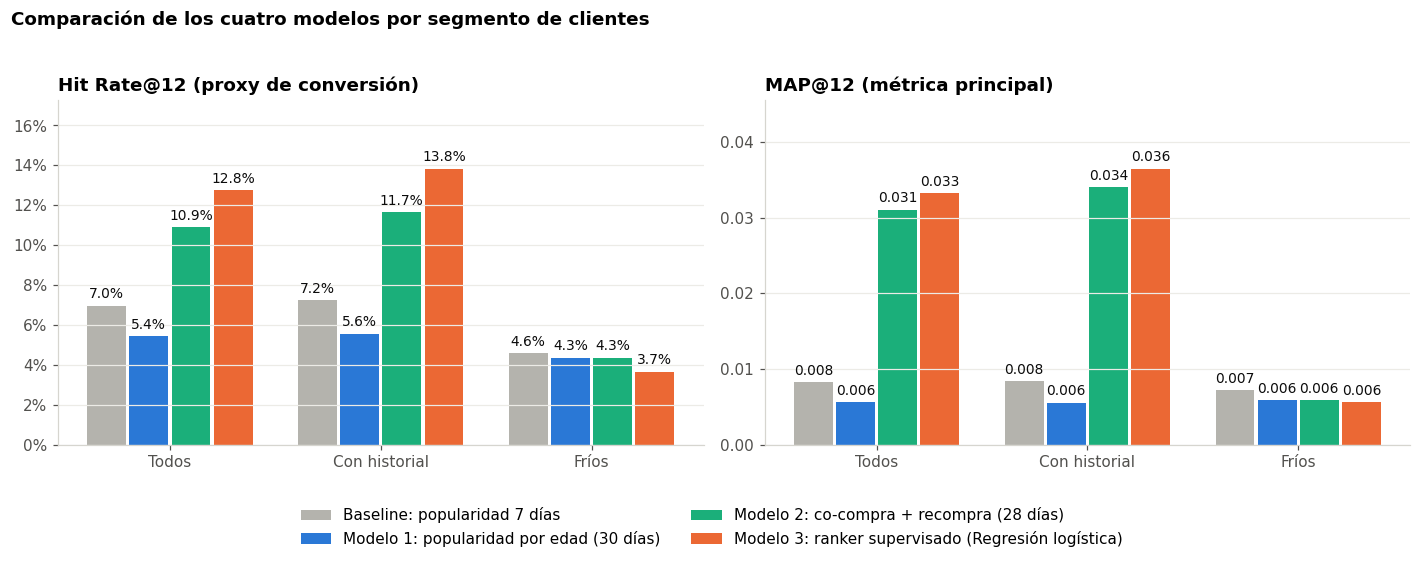

In [17]:
modelos_orden = [baseline.nombre, modelo1.nombre, modelo2.nombre, modelo3.nombre]
colores_m = [GRIS, AZUL, VERDE, NARANJA]
grupos = list(segmentos)
x, w = np.arange(len(grupos)), 0.2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, fmt, titulo in [(axes[0], "Hit Rate@12", lambda v: f"{v:.1%}", "Hit Rate@12 (proxy de conversión)"),
                             (axes[1], "MAP@12", lambda v: f"{v:.3f}", "MAP@12 (métrica principal)")]:
    for j, (nombre, color) in enumerate(zip(modelos_orden, colores_m)):
        vals = [comparacion[(comparacion["Modelo"] == nombre) & (comparacion["Grupo"] == g)][col].iloc[0] for g in grupos]
        b = ax.bar(x + (j - 1.5) * w, vals, w * 0.92, color=color, label=nombre)
        rotular(ax, b, fmt)
    ax.set_xticks(x, grupos); ax.set_title(titulo); ax.set_ylim(0, comparacion[col].max() * 1.25)
    if col == "Hit Rate@12":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.16))
fig.suptitle("Comparación de los cuatro modelos por segmento de clientes", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.03)
fig.tight_layout(); guardar(fig, "11_comparacion_modelos"); plt.show()

#### Hallazgo
El gráfico resume la comparación: **barra más alta = mejor**. Se ve en qué segmento cada modelo marca la diferencia y dónde los modelos de historial empatan con la edad (clientes fríos).

#### Implicancia para el negocio
Es el gráfico que resume los resultados: muestra en una imagen que la personalización supera a la estrategia actual.

### Paso 5.6 · ¿Las mejoras son reales o pueden ser azar?
**Qué hace:** para tres comparaciones clave, repite la evaluación 1.000 veces con clientes sorteados (*bootstrap*) y calcula el rango donde cae la diferencia el 95% de las veces (**intervalo de confianza**).
- **Robusta:** el rango no incluye el 0 → la mejora (o empeora) es real.
- **No concluyente:** el rango incluye el 0 → con estos clientes no alcanza para afirmarlo.



In [18]:
# ¿Las mejoras son robustas? Intervalos de confianza pareados (bootstrap)
for titulo, seg, a, b in [("Modelo 2 vs baseline · con historial", "Con historial", baseline, modelo2),
                          ("Modelo 3 vs Modelo 2 · con historial", "Con historial", modelo2, modelo3),
                          ("Modelo 3 vs Modelo 1 · fríos", "Fríos", modelo1, modelo3)]:
    print(titulo)
    for nombre, r in bootstrap_diferencia(segmentos[seg], a.recomendar, b.recomendar).items():
        f = "{:+.4f}" if nombre == "MAP@12" else "{:+.2%}"
        print(f"   {nombre}: diferencia {f.format(r['diferencia'])}  IC 95% [{f.format(r['ic_bajo'])}, {f.format(r['ic_alto'])}]",
              "-> robusta" if r["robusta"] else "-> no concluyente")

def val(m, g, col):
    return comparacion[(comparacion["Modelo"] == m) & (comparacion["Grupo"] == g)][col].iloc[0]
print()
for g in grupos:
    mejor = max(modelos_orden, key=lambda m: val(m, g, "MAP@12"))
    print(f"Mejor modelo en '{g}' por MAP@12: {mejor}")
print("Prendas distintas recomendadas ->", " · ".join(f"{m.split(':')[0]}: {val(m, 'Todos', 'Prendas distintas')}" for m in modelos_orden))

Modelo 2 vs baseline · con historial
   MAP@12: diferencia +0.0256  IC 95% [+0.0205, +0.0308] -> robusta
   Hit Rate@12: diferencia +4.40%  IC 95% [+3.06%, +5.61%] -> robusta
Modelo 3 vs Modelo 2 · con historial
   MAP@12: diferencia +0.0024  IC 95% [-0.0002, +0.0050] -> no concluyente
   Hit Rate@12: diferencia +2.17%  IC 95% [+1.48%, +2.90%] -> robusta
Modelo 3 vs Modelo 1 · fríos
   MAP@12: diferencia -0.0003  IC 95% [-0.0068, +0.0079] -> no concluyente
   Hit Rate@12: diferencia -0.69%  IC 95% [-2.52%, +1.14%] -> no concluyente

Mejor modelo en 'Todos' por MAP@12: Modelo 3: ranker supervisado (Regresión logística)
Mejor modelo en 'Con historial' por MAP@12: Modelo 3: ranker supervisado (Regresión logística)
Mejor modelo en 'Fríos' por MAP@12: Baseline: popularidad 7 días
Prendas distintas recomendadas -> Baseline: 12 · Modelo 1: 54 · Modelo 2: 10247 · Modelo 3: 9205


### Cómo leer los resultados
- **Con historial:** es donde los Modelos 2 y 3 pueden marcar diferencia, porque usan lo que el cliente ya compró. Los intervalos de confianza indican si cada mejora es **robusta** o podría ser azar.
- **Fríos:** el Modelo 2 da **exactamente lo mismo que el Modelo 1**, porque sin historial usa su respaldo por edad (coherente con el diseño). El Modelo 3 puede reordenar los candidatos con la tendencia y la popularidad en el tramo: el intervalo dice si eso ayuda de verdad.
- **Prendas distintas:** cuantas más prendas distintas recomienda un modelo, más **reparte la visibilidad** del catálogo (cola larga) en lugar de concentrarla en 12.
- El **Recall@12** (columna de la tabla) es el proxy del KPI secundario, **productos por pedido**: muestra qué parte de lo que el cliente terminó comprando anticipamos.

### Paso 5.7 · Verificación de las hipótesis
**Qué hace:** aplica a cada hipótesis el criterio definido al inicio del notebook y escribe el veredicto con los números reales: se cumple, mejora pero no es concluyente, no se cumple.



VERIFICACIÓN DE HIPÓTESIS
   H1 · No se cumple            · Edad > lo más vendido en clientes nuevos
   H2 · Se cumple               · Historial (co-compra) > edad en clientes con historial
   H3 · Mejora, no concluyente  · Supervisado > no supervisado en clientes con historial
   H4 · Se cumple               · Lo reciente (7 días) > lo histórico
   H5 · Se cumple               · Personalizar reparte la visibilidad del catálogo


,Hipótesis,Enunciado,Veredicto,Evidencia
0,H1,Edad > lo más vendido en clientes nuevos,No se cumple,MAP@12 0.0072 → 0.0058 (-19%) · Hit Rate 4.6 →...
1,H2,Historial (co-compra) > edad en clientes con h...,Se cumple,MAP@12 0.0055 → 0.0340 (+515%) · Hit Rate 5.6 ...
2,H3,Supervisado > no supervisado en clientes con h...,"Mejora, no concluyente",MAP@12 0.0340 → 0.0364 (+7%) · Hit Rate 11.7 →...
3,H4,Lo reciente (7 días) > lo histórico,Se cumple,Validación · MAP@12 0.0048 → 0.0073 · Hit Rate...
4,H5,Personalizar reparte la visibilidad del catálogo,Se cumple,Prendas distintas recomendadas: Baseline 12 → ...


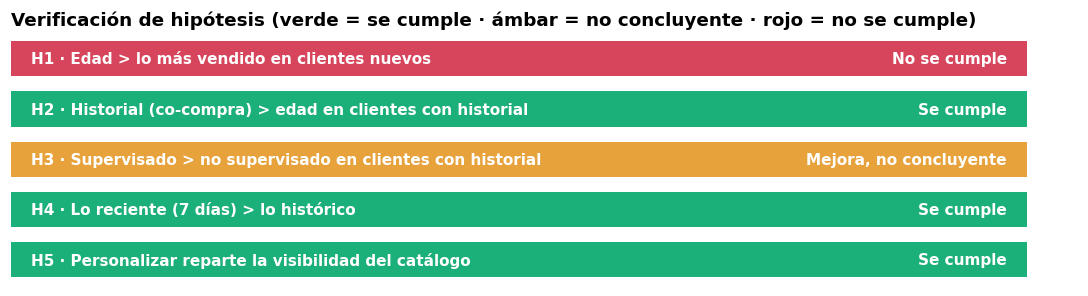

In [19]:
def veredicto_duelo(seg, a, b):
    ma, mb_ = v(a, seg, "MAP@12"), v(b, seg, "MAP@12")
    ha, hb = v(a, seg, "Hit Rate@12"), v(b, seg, "Hit Rate@12")
    obj = {"Baseline": baseline, "M1 · Edad": modelo1, "M2 · Co-compra (no sup.)": modelo2, "M3 · Ranker (sup.)": modelo3}
    ic = bootstrap_diferencia(segmentos[seg], obj[b].recomendar, obj[a].recomendar)["MAP@12"]
    if ma > mb_ and ha > hb and ic["ic_bajo"] > 0:
        res = "Se cumple"
    elif ma > mb_ or ha > hb:
        res = "Mejora, no concluyente"
    else:
        res = "No se cumple"
    evid = (f"MAP@12 {mb_:.4f} → {ma:.4f} ({(ma / mb_ - 1) * 100 if mb_ else float('nan'):+.0f}%) · "
            f"Hit Rate {hb * 100:.1f} → {ha * 100:.1f} de cada 100 · IC 95% MAP [{ic['ic_bajo']:+.4f}, {ic['ic_alto']:+.4f}]")
    return res, evid

hip = []
r, e = veredicto_duelo("Fríos", "M1 · Edad", "Baseline")
hip.append(("H1", "Edad > lo más vendido en clientes nuevos", r, e))
r, e = veredicto_duelo("Con historial", "M2 · Co-compra (no sup.)", "M1 · Edad")
hip.append(("H2", "Historial (co-compra) > edad en clientes con historial", r, e))
r, e = veredicto_duelo("Con historial", "M3 · Ranker (sup.)", "M2 · Co-compra (no sup.)")
hip.append(("H3", "Supervisado > no supervisado en clientes con historial", r, e))

vb = v_base.set_index("Modelo")
rec7, hist = vb.loc["Baseline: popularidad 7 días"], vb.loc["Baseline: popularidad histórica"]
ok4 = rec7["MAP@12"] > hist["MAP@12"] and rec7["Hit Rate@12"] > hist["Hit Rate@12"]
hip.append(("H4", "Lo reciente (7 días) > lo histórico", "Se cumple" if ok4 else ("Mejora, no concluyente"
            if rec7["MAP@12"] > hist["MAP@12"] else "No se cumple"),
            f"Validación · MAP@12 {hist['MAP@12']:.4f} → {rec7['MAP@12']:.4f} · Hit Rate {hist['Hit Rate@12'] * 100:.1f} → {rec7['Hit Rate@12'] * 100:.1f} de cada 100"))

mejor_m = max(TRES, key=lambda m: v(m, "Todos", "MAP@12"))
div_b, div_m = v("Baseline", "Todos", "Prendas distintas"), v(mejor_m, "Todos", "Prendas distintas")
hip.append(("H5", "Personalizar reparte la visibilidad del catálogo", "Se cumple" if div_m > div_b else "No se cumple",
            f"Prendas distintas recomendadas: Baseline {int(div_b):,} → {mejor_m} {int(div_m):,}"))

hipotesis = pd.DataFrame(hip, columns=["Hipótesis", "Enunciado", "Veredicto", "Evidencia"])
print("VERIFICACIÓN DE HIPÓTESIS")
for _, h in hipotesis.iterrows():
    print(f"   {h['Hipótesis']} · {h['Veredicto']:<26} · {h['Enunciado']}")
display(hipotesis)

# Gráfico: semáforo de hipótesis
colores_v = {"S": VERDE, "M": "#e7a23b", "N": "#d6455b"}
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, h in enumerate(hipotesis.itertuples()):
    c = colores_v[h.Veredicto[0]]
    ax.barh(i, 1, color=c, height=0.7)
    ax.text(0.02, i, f"{h.Hipótesis} · {h.Enunciado}", va="center", fontsize=10, color="white", fontweight="bold")
    ax.text(0.98, i, h.Veredicto[2:], va="center", ha="right", fontsize=10, color="white", fontweight="bold")
ax.set_ylim(len(hipotesis) - 0.5, -0.5); ax.axis("off")
ax.set_title("Verificación de hipótesis (verde = se cumple · ámbar = no concluyente · rojo = no se cumple)")
fig.tight_layout(); guardar(fig, "16_hipotesis"); plt.show()

#### Hallazgo
La tabla resume **qué creíamos y qué mostraron los datos**. Cada veredicto incluye su evidencia (antes → después) y, para H1–H3, el intervalo de confianza que indica si la diferencia es real o podría ser azar.

#### Implicancia para el negocio
- **Hipótesis que se cumplen:** son decisiones que H&M puede tomar **con respaldo de datos** (por ejemplo, actualizar las recomendaciones cada semana si se cumple H4).
- **Hipótesis no concluyentes:** la dirección es correcta pero hacen falta **más datos**. Se recomienda confirmarlas con un **test A/B** antes de invertir.
- **Hipótesis que no se cumplen:** evitan invertir en una solución que no funciona. **Rechazar una hipótesis también es un resultado valioso.**

---
# 6. ¿Qué modelo ganó y por qué?

Esta sección responde **en un solo lugar** la pregunta central del proyecto. Compara **los 4 modelos** con **todas las métricas**, conectadas a los **KPIs de negocio**, y explica **por qué gana el ganador**.

**Regla para declarar al ganador (definida antes de ver el test):**
1. Se compara por **tipo de cliente**, porque cada modelo usa información distinta: el cliente nuevo no tiene historial.
2. Gana el modelo con **mayor MAP@12**, la métrica principal: mide si acertamos **y** si pusimos lo correcto arriba.
3. Las demás métricas explican **por qué** gana y **qué KPI de negocio** mueve.
4. El **intervalo de confianza** dice si la ventaja es real o podría ser azar.

| KPI de negocio | Métrica | Qué significa |
|---|---|---|
| **Experiencia** (métrica principal) | MAP@12 | Acertamos y lo correcto aparece arriba |
| **Conversión** (KPI principal) | Hit Rate@12 | De cada 100 clientes, cuántos compran algo de la lista |
| **Productos por pedido** | Recall@12 | Qué parte de su compra anticipamos |
| **Uso de la vitrina** | Precision@12 | Qué parte de los 12 lugares se aprovecha |
| **Salud del catálogo** | Prendas distintas | A cuántas prendas damos visibilidad |

### Paso 6.1 · Tabla completa: los 4 modelos, todas las métricas y KPIs
**Qué hace:** arma una tabla por tipo de cliente con los 4 modelos en columnas y los 5 KPIs en filas. Marca con (mejor) al ganador de cada KPI e indica cuánto mejora frente a hoy (baseline).

In [20]:
KPIS = [("Experiencia", "MAP@12"), ("Conversión", "Hit Rate@12"), ("Productos por pedido", "Recall@12"),
        ("Uso de la vitrina", "Precision@12"), ("Salud del catálogo", "Prendas distintas")]
OBJ = {"Baseline": baseline, "M1 · Edad": modelo1, "M2 · Co-compra (no sup.)": modelo2, "M3 · Ranker (sup.)": modelo3}

def fmt_kpi(met, x):
    if met in ("Hit Rate@12", "Recall@12", "Precision@12"):
        return f"{x * 100:.2f}%"
    return f"{x:.4f}" if met == "MAP@12" else f"{int(x):,}"

ganador_seg = {}
for seg in segmentos:
    filas = []
    for kpi, met in KPIS:
        vals = {m: v(m, seg, met) for m in TRES}
        gan = max(vals, key=vals.get)
        base = vals["Baseline"]
        fila = {"KPI": kpi, "Métrica": met}
        fila.update({m: fmt_kpi(met, x) + (" (mejor)" if m == gan else "") for m, x in vals.items()})
        fila["Ganador"] = gan
        fila["vs hoy (baseline)"] = "—" if gan == "Baseline" or not base else f"{(vals[gan] / base - 1) * 100:+.0f}%"
        filas.append(fila)
    ganador_seg[seg] = max(TRES, key=lambda m: v(m, seg, "MAP@12"))
    print(f"\n━━━ {seg.upper()} ({len(segmentos[seg]):,} clientes) · GANADOR: {ganador_seg[seg]} ━━━")
    display(pd.DataFrame(filas).set_index("KPI"))


━━━ TODOS (4,162 clientes) · GANADOR: M3 · Ranker (sup.) ━━━


,Métrica,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,vs hoy (baseline)
KPI,,,,,,,
Experiencia,MAP@12,0.0083,0.0056,0.0311,0.0332,M3 · Ranker (sup.),+302%
Conversión,Hit Rate@12,6.97%,5.43%,10.88%,12.76%,M3 · Ranker (sup.),+83%
Productos por pedido,Recall@12,2.71%,2.06%,6.00%,6.70%,M3 · Ranker (sup.),+148%
Uso de la vitrina,Precision@12,0.65%,0.48%,1.14%,1.27%,M3 · Ranker (sup.),+95%
Salud del catálogo,Prendas distintas,12,54,"10,247","9,205",M2 · Co-compra (no sup.),+85292%



━━━ CON HISTORIAL (3,725 clientes) · GANADOR: M3 · Ranker (sup.) ━━━


,Métrica,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,vs hoy (baseline)
KPI,,,,,,,
Experiencia,MAP@12,0.0084,0.0055,0.0340,0.0364,M3 · Ranker (sup.),+335%
Conversión,Hit Rate@12,7.25%,5.56%,11.65%,13.83%,M3 · Ranker (sup.),+91%
Productos por pedido,Recall@12,2.78%,2.08%,6.49%,7.30%,M3 · Ranker (sup.),+163%
Uso de la vitrina,Precision@12,0.67%,0.49%,1.22%,1.38%,M3 · Ranker (sup.),+105%
Salud del catálogo,Prendas distintas,12,54,"10,247","9,205",M2 · Co-compra (no sup.),+85292%



━━━ FRÍOS (437 clientes) · GANADOR: Baseline ━━━


,Métrica,Baseline,M1 · Edad,M2 · Co-compra (no sup.),M3 · Ranker (sup.),Ganador,vs hoy (baseline)
KPI,,,,,,,
Experiencia,MAP@12,0.0072,0.0058,0.0058,0.0056,Baseline,—
Conversión,Hit Rate@12,4.58%,4.35%,4.35%,3.66%,Baseline,—
Productos por pedido,Recall@12,2.07%,1.86%,1.86%,1.60%,Baseline,—
Uso de la vitrina,Precision@12,0.46%,0.38%,0.38%,0.31%,Baseline,—
Salud del catálogo,Prendas distintas,12,44,44,20,M1 · Edad,+267%


### Paso 6.2 · Gráfico del ganador
**Qué hace:** para cada tipo de cliente muestra los 4 modelos en las dos métricas clave: **conversión** (Hit Rate@12) y **experiencia** (MAP@12). **El ganador está en verde **, lo que H&M hace hoy en gris oscuro y los demás modelos en gris claro.

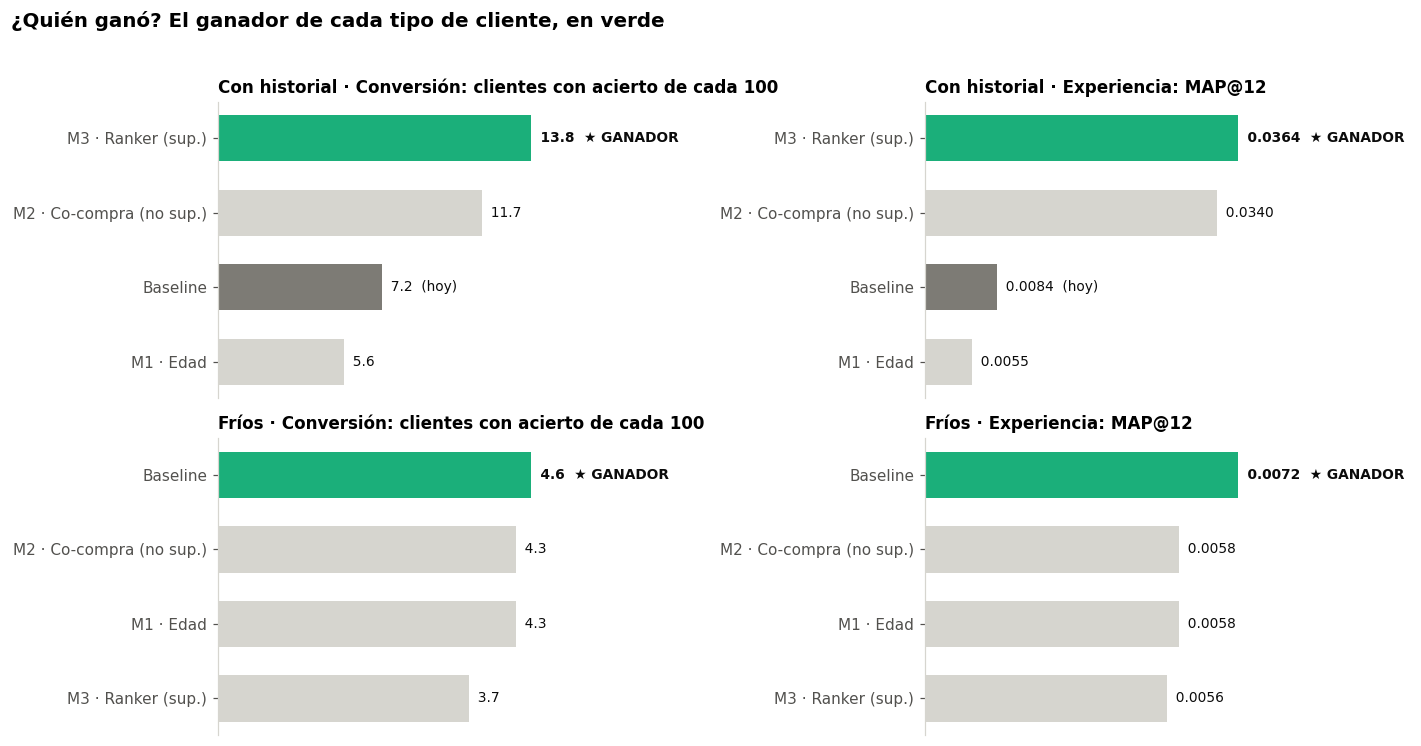

In [21]:
segs_g = ["Con historial", "Fríos"]
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6))
for r, seg in enumerate(segs_g):
    gan = ganador_seg[seg]
    for c, (met, titulo, f) in enumerate([("Hit Rate@12", "Conversión: clientes con acierto de cada 100", lambda x: f"{x:.1f}"),
                                          ("MAP@12", "Experiencia: MAP@12", lambda x: f"{x:.4f}")]):
        ax = axes[r, c]
        orden = sorted(TRES, key=lambda m: v(m, seg, met))
        vals = [v(m, seg, met) * (100 if met == "Hit Rate@12" else 1) for m in orden]
        colores = [VERDE if m == gan else ("#7d7b75" if m == "Baseline" else "#d6d5cf") for m in orden]
        barras = ax.barh(orden, vals, color=colores, height=0.62)
        for b, m, x in zip(barras, orden, vals):
            etiqueta = f"  {f(x)}" + ("  (ganador)" if m == gan else ("  (hoy)" if m == "Baseline" else ""))
            ax.text(b.get_width(), b.get_y() + b.get_height() / 2, etiqueta, va="center", fontsize=9,
                    color=TEXTO, fontweight="bold" if m == gan else "normal")
        ax.set_xlim(0, max(vals) * 1.55); ax.grid(False); ax.set_xticks([])
        ax.spines["bottom"].set_visible(False)
        ax.set_title(f"{seg} · {titulo}", fontsize=11)
fig.suptitle("¿Quién ganó? El ganador de cada tipo de cliente, en verde", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.02)
fig.tight_layout(); guardar(fig, "18_ganador"); plt.show()

### Paso 6.3 · ¿Por qué ganó? (explicación automática con los números)
**Qué hace:** para cada tipo de cliente explica por qué ganó el ganador:
1. **Cuántos KPIs ganó** de los 5.
2. **Cuánto mejora la conversión** frente a hoy, en clientes de cada 100.
3. **Si la ventaja es real o podría ser azar** (intervalo de confianza).
4. **Qué información aprovecha** que los demás no.

In [22]:
razon_modelo = {
    "Baseline": "muestra lo más vendido a todos; no usa información del cliente",
    "M1 · Edad": "usa la edad del cliente, la única señal disponible antes de su primera compra",
    "M2 · Co-compra (no sup.)": "aprovecha lo que el cliente ya compró y qué prendas se compran juntas",
    "M3 · Ranker (sup.)": "aprende a combinar todas las señales (historial, edad, tendencia, precio) para estimar la probabilidad de compra",
}
top_senales = ", ".join(importancia.sort_values(ascending=False).head(3).index)
for seg in segs_g:
    gan = ganador_seg[seg]
    kpis_ganados = [k for k, met in KPIS if max(TRES, key=lambda m: v(m, seg, met)) == gan]
    hb, hg = v("Baseline", seg, "Hit Rate@12") * 100, v(gan, seg, "Hit Rate@12") * 100
    segundo = max([m for m in TRES if m != gan], key=lambda m: v(m, seg, "MAP@12"))
    empata = v(segundo, seg, "MAP@12") == v(gan, seg, "MAP@12")
    print("═" * 82)
    print(f"{seg.upper()}: GANA {gan}")
    print("═" * 82)
    print(f"  1. Gana {len(kpis_ganados)} de 5 KPIs: {', '.join(kpis_ganados) if kpis_ganados else '—'}")
    print(f"  2. Conversión: {hg:.1f} de cada 100 clientes encuentran algo, contra {hb:.1f} hoy "
          f"→ {hg - hb:+.1f} clientes de cada 100 ({(hg / hb - 1) * 100 if hb else float('nan'):+.0f}%)")
    if gan != "Baseline":
        ic = bootstrap_diferencia(segmentos[seg], baseline.recomendar, OBJ[gan].recomendar)["MAP@12"]
        robusto = "la ventaja frente a hoy es REAL (el intervalo no incluye el 0)" if ic["ic_bajo"] > 0 else \
                  "la ventaja frente a hoy NO es concluyente con esta cantidad de clientes"
        print(f"  3. {robusto} · IC 95% MAP@12 [{ic['ic_bajo']:+.4f}, {ic['ic_alto']:+.4f}]")
        ic2 = bootstrap_diferencia(segmentos[seg], OBJ[segundo].recomendar, OBJ[gan].recomendar)["MAP@12"]
        if empata:
            print(f"     Empata con {segundo}: dan las mismas recomendaciones a estos clientes (sin historial, el modelo de co-compra usa la edad como respaldo).")
        else:
            print(f"     Frente al 2.º ({segundo}): " + ("ventaja real" if ic2["ic_bajo"] > 0 else "ventaja no concluyente con esta cantidad de clientes"))
    print(f"  4. Por qué: {razon_modelo[gan]}.")
    if gan in ("M2 · Co-compra (no sup.)", "M3 · Ranker (sup.)"):
        print(f"     Las señales que más predicen una compra son: {top_senales}.")
print("═" * 82)

══════════════════════════════════════════════════════════════════════════════════
CON HISTORIAL: GANA M3 · Ranker (sup.)
══════════════════════════════════════════════════════════════════════════════════
  1. Gana 4 de 5 KPIs: Experiencia, Conversión, Productos por pedido, Uso de la vitrina
  2. Conversión: 13.8 de cada 100 clientes encuentran algo, contra 7.2 hoy → +6.6 clientes de cada 100 (+91%)
  3. la ventaja frente a hoy es REAL (el intervalo no incluye el 0) · IC 95% MAP@12 [+0.0234, +0.0326]
     Frente al 2.º (M2 · Co-compra (no sup.)): ventaja no concluyente con esta cantidad de clientes
  4. Por qué: aprende a combinar todas las señales (historial, edad, tendencia, precio) para estimar la probabilidad de compra.
     Las señales que más predicen una compra son: puntaje_cocompra, n_compras, dias_desde_ultima.
══════════════════════════════════════════════════════════════════════════════════
FRÍOS: GANA Baseline
════════════════════════════════════════════════════════════════

### Conclusión por métricas y KPIs
- **Experiencia (MAP@12)** define al ganador: es la métrica más exigente porque premia acertar **y** ordenar bien.
- **Conversión (Hit Rate@12)** traduce el resultado a negocio: *"X clientes más de cada 100 encuentran algo que compran"*.
- **Productos por pedido (Recall@12)**: si el ganador también gana aquí, además de convertir ayuda a **llenar el carrito**.
- **Uso de la vitrina (Precision@12)**: indica cuántos de los 12 lugares de la pantalla trabajan para vender.
- **Salud del catálogo**: un ganador que también recomienda **muchas prendas distintas** reparte la demanda y evita mostrar siempre lo mismo.
- **El intervalo de confianza** separa las ventajas **reales** de las que podrían ser **azar**: solo las reales se presentan como logros firmes.

### Implicancia para el negocio
El ganador **no es el mismo** para todos los clientes, porque no sabemos lo mismo de todos. Por eso se aplica el modelo ganador **según el tipo de cliente** (sistema por etapas, sección 7). Así cada cliente recibe la mejor recomendación posible con la información disponible.

### Paso 6.4 · Ganador único: el modelo que implementamos
En producción conviene **un solo modelo**: es más simple de mantener, de explicar y de monitorear. Los resultados anteriores permiten elegirlo con evidencia:

1. **Para clientes con historial**, los modelos que usan el historial (co-compra y ranker) superan claramente a lo más vendido.
2. **Para clientes nuevos**, la edad **no** superó a lo más vendido (hipótesis H1). Por eso el respaldo para un cliente sin historial es **lo más vendido de la semana**, no la edad.
3. Se arma el candidato **"Modelo final"** (sistema por etapas) = el **modelo personalizado con mayor MAP@12 en validación** (co-compra o ranker) para los clientes con historial **+ lo más vendido de la semana** para los clientes nuevos, y se compara con los demás.

**Regla para el ganador único (fijada antes de ver el test):** el candidato con **mayor MAP@12 en validación sobre todos los clientes**. El test confirma el resultado.

Personalizado elegido para clientes con historial: ranker (Regresión logística) (MAP@12 en validación: ranker 0.0323 · co-compra 0.0299)
Validación (09-15/09) · candidatos a modelo único:


,MAP@12,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
Candidato,,,,
Modelo final: ranker (Regresión logística) + lo más vendido para nuevos,0.0328,13.25,6.50,1.39
Modelo 3: ranker (Regresión logística),0.0323,13.34,6.49,1.39
Modelo 2: co-compra + recompra (28 días),0.0299,11.50,6.16,1.24
Modelo 1: popularidad por edad (30 días),0.0080,6.29,2.39,0.58
Baseline: popularidad 7 días,0.0073,6.13,2.16,0.54


Test (16-22/09) · modelo final vs lo que H&M hace hoy y los demás modelos:


Clientes  \
Grupo         Modelo
Con historial Modelo 3: ranker supervisado (Regresión logística)      3725
              Modelo final: ranker (Regresión logística) + lo...      3725
              Modelo 2: co-compra + recompra (28 días)                3725
              Baseline: popularidad 7 días                            3725
Fríos         Baseline: popularidad 7 días                             437
              Modelo final: ranker (Regresión logística) + lo...       437
              Modelo 2: co-compra + recompra (28 días)                 437
              Modelo 3: ranker supervisado (Regresión logística)       437
Todos         Modelo final: ranker (Regresión logística) + lo...      4162
              Modelo 3: ranker supervisado (Regresión logística)      4162
              Modelo 2: co-compra + recompra (28 días)                4162
              Baseline: popularidad 7 días                            4162

                                                                  MAP@12  \
Grupo         Modelo
Con historial Modelo 3: ranker supervisado (Regresión logística)  0.0364
              Modelo final: ranker (Regresión logística) + lo...  0.0364
              Modelo 2: co-compra + recompra (28 días)            0.0340
              Baseline: popularidad 7 días                        0.0084
Fríos         Baseline: popularidad 7 días                        0.0072
              Modelo final: ranker (Regresión logística) + lo...  0.0072
              Modelo 2: co-compra + recompra (28 días)            0.0058
              Modelo 3: ranker supervisado (Regresión logística)  0.0056
Todos         Modelo final: ranker (Regresión logística) + lo...  0.0334
              Modelo 3: ranker supervisado (Regresión logística)  0.0332
              Modelo 2: co-compra + recompra (28 días)            0.0311
              Baseline: popularidad 7 días                        0.0083

                                                                  Prendas distintas  \
Grupo         Modelo
Con historial Modelo 3: ranker supervisado (Regresión logística)               9205
              Modelo final: ranker (Regresión logística) + lo...               9205
              Modelo 2: co-compra + recompra (28 días)                        10247
              Baseline: popularidad 7 días                                       12
Fríos         Baseline: popularidad 7 días                                       12
              Modelo final: ranker (Regresión logística) + lo...                 12
              Modelo 2: co-compra + recompra (28 días)                           44
              Modelo 3: ranker supervisado (Regresión logística)                 20
Todos         Modelo final: ranker (Regresión logística) + lo...               9205
              Modelo 3: ranker supervisado (Regresión logística)               9205
              Modelo 2: co-compra + recompra (28 días)                        10247
              Baseline: popularidad 7 días                                       12

                                                                  Hit Rate@12 (%)  \
Grupo         Modelo
Con historial Modelo 3: ranker supervisado (Regresión logística)            13.83
              Modelo final: ranker (Regresión logística) + lo...            13.83
              Modelo 2: co-compra + recompra (28 días)                      11.65
              Baseline: popularidad 7 días                                   7.25
Fríos         Baseline: popularidad 7 días                                   4.58
              Modelo final: ranker (Regresión logística) + lo...             4.58
              Modelo 2: co-compra + recompra (28 días)                       4.35
              Modelo 3: ranker supervisado (Regresión logística)             3.66
Todos         Modelo final: ranker (Regresión logística) + lo...            12.85
              Modelo 3: ranker supervisado (Regresión logística)            12.76
              Modelo 2: co-compra + recompra (28 

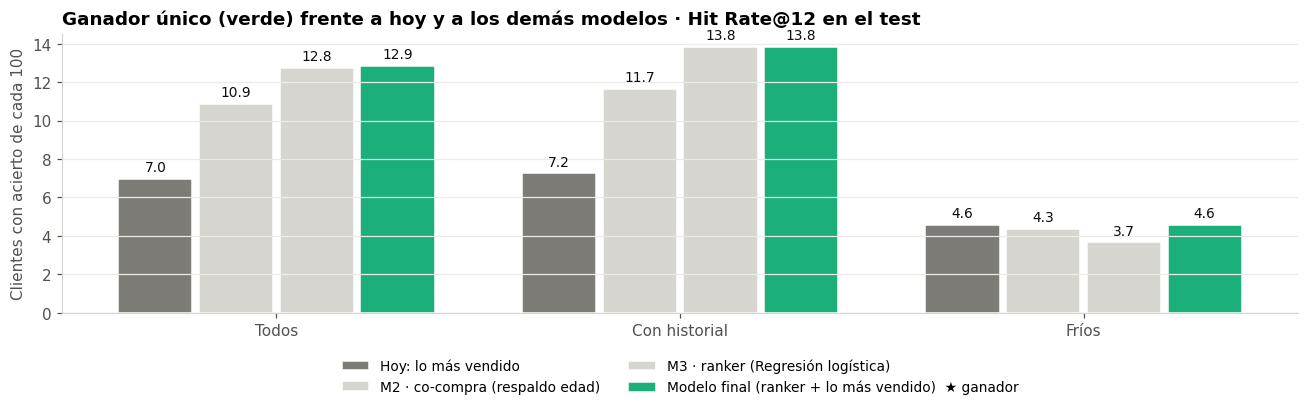

════════════════════════════════════════════════════════════════════════════════════
Ganador único (mayor MAP@12 en validación): Modelo final: ranker (Regresión logística) + lo más vendido para nuevos
════════════════════════════════════════════════════════════════════════════════════
  1. Validación: MAP@12 0.0328 vs 0.0323 del 2.º (Modelo 3: ranker (Regresión logística)).
  2. Test · Todos        : 12.9 de cada 100 clientes con acierto vs 7.0 hoy (+5.9).
  2. Test · Con historial: 13.8 de cada 100 clientes con acierto vs 7.2 hoy (+6.6).
  2. Test · Fríos        : 4.6 de cada 100 clientes con acierto vs 4.6 hoy (+0.0).
  3. Clientes con historial: la mejora frente a hoy es REAL (IC 95% MAP@12 [+0.0234, +0.0326]).
  4. Clientes con historial: usa el ranker (Regresión logística), el personalizado con mayor MAP@12 en validación.
  5. Clientes nuevos: recibe lo más vendido de la semana, la mejor opción demostrada sin historial (H1: la edad no lo superó).
     Así ningún segmento queda por

In [23]:
dias_b = baseline.dias or 7
# Personalizado para clientes con historial: el de mayor MAP@12 en validación (ranker o co-compra)
map_ranker_val = algoritmos.set_index("clave").loc[MEJOR_ALG, "MAP@12"]
map_m2_val = v_m2.set_index("Modelo").loc[modelo2.nombre, "MAP@12"]
USAR_RANKER = map_ranker_val >= map_m2_val
ETQ_FINAL = f"ranker ({ALGORITMOS[MEJOR_ALG]})" if USAR_RANKER else "co-compra"
def cocompra_hasta(fecha):
    respaldo = PopularidadReciente(dias_b).fit(train, fecha)
    return CoCompraRecompra(respaldo, dias_pares=modelo2.dias_pares, peso_recompra=modelo2.peso_recompra).fit(train, fecha)
final_val = modelo_final(modelo3_val if USAR_RANKER else cocompra_hasta(VAL), train, VAL, dias_b, ETQ_FINAL)
print(f"Personalizado elegido para clientes con historial: {ETQ_FINAL} "
      f"(MAP@12 en validación: ranker {map_ranker_val:.4f} · co-compra {map_m2_val:.4f})")

# 1. Candidatos a modelo único, medidos en VALIDACIÓN (todos los clientes de la semana 09-15/09)
cand = [(baseline.nombre, v_base.set_index("Modelo").loc[baseline.nombre]),
        (modelo1.nombre, v_m1.set_index("Modelo").loc[modelo1.nombre]),
        (modelo2.nombre, v_m2.set_index("Modelo").loc[modelo2.nombre]),
        (f"Modelo 3: ranker ({ALGORITMOS[MEJOR_ALG]})", algoritmos.set_index("clave").loc[MEJOR_ALG]),
        (final_val.nombre, pd.Series(metricas(val_c, final_val.recomendar)))]
val_unico = pd.DataFrame([{"Candidato": n, "MAP@12": r["MAP@12"], "Hit Rate@12": r["Hit Rate@12"],
                           "Recall@12": r["Recall@12"], "Precision@12": r["Precision@12"]} for n, r in cand])
GANADOR_UNICO = val_unico.loc[val_unico["MAP@12"].idxmax(), "Candidato"]
print("Validación (09-15/09) · candidatos a modelo único:")
display(tabla_bonita(val_unico.sort_values("MAP@12", ascending=False)).set_index("Candidato"))

# 2. Modelo final en el TEST, por segmento
final = modelo_final(modelo3 if USAR_RANKER else cocompra_hasta(CORTE_TEST), train, CORTE_TEST, dias_b, ETQ_FINAL)
res_final = pd.DataFrame([{"Modelo": final.nombre, "Grupo": g, "Clientes": len(comp), **metricas(comp, final.recomendar)}
                          for g, comp in segmentos.items()])
OBJ_TEST = {baseline.nombre: baseline, modelo1.nombre: modelo1, modelo2.nombre: modelo2,
            modelo3.nombre: modelo3, final.nombre: final}
comp_unico = pd.concat([comparacion, res_final], ignore_index=True)
nombre_gan_test = {final_val.nombre: final.nombre}.get(GANADOR_UNICO, GANADOR_UNICO)
if nombre_gan_test.startswith("Modelo 3"):
    nombre_gan_test = modelo3.nombre
print("Test (16-22/09) · modelo final vs lo que H&M hace hoy y los demás modelos:")
display(tabla_bonita(comp_unico[comp_unico["Modelo"].isin([baseline.nombre, modelo2.nombre, modelo3.nombre, final.nombre])]
                     .sort_values(["Grupo", "MAP@12"], ascending=[True, False])).set_index(["Grupo", "Modelo"]))

# 3. Gráfico
def vu(m, g, met):
    return comp_unico[(comp_unico["Modelo"] == m) & (comp_unico["Grupo"] == g)][met].iloc[0]
mods = [baseline.nombre, modelo2.nombre, modelo3.nombre, final.nombre]
etiq = {baseline.nombre: "Hoy: lo más vendido", modelo2.nombre: "M2 · co-compra (respaldo edad)",
        modelo3.nombre: f"M3 · ranker ({ALGORITMOS[MEJOR_ALG]})", final.nombre: f"Modelo final ({ETQ_FINAL.split(' (')[0]} + lo más vendido)"}
fig, ax = plt.subplots(figsize=(12, 3.9))
xs = np.arange(3); w = 0.2
for j, m in enumerate(mods):
    color = VERDE if m == nombre_gan_test else ("#7d7b75" if m == baseline.nombre else "#d6d5cf")
    barras = ax.bar(xs + (j - 1.5) * w, [vu(m, g, "Hit Rate@12") * 100 for g in segmentos], w * 0.92, color=color,
                    label=etiq[m] + ("  (ganador)" if m == nombre_gan_test else ""), edgecolor="white")
    rotular(ax, barras, lambda x: f"{x:.1f}")
ax.set_xticks(xs, list(segmentos)); ax.set_ylabel("Clientes con acierto de cada 100")
ax.set_title("Ganador único (verde) frente a hoy y a los demás modelos · Hit Rate@12 en el test")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
fig.tight_layout(); guardar(fig, "20_ganador_unico"); plt.show()

# 4. ¿Por qué ganó?
print("═" * 84)
print(f"Ganador único (mayor MAP@12 en validación): {GANADOR_UNICO}")
print("═" * 84)
orden_val = val_unico.sort_values("MAP@12", ascending=False).reset_index(drop=True)
seg_val_g = orden_val.iloc[1]
print(f"  1. Validación: MAP@12 {orden_val.iloc[0]['MAP@12']:.4f} vs {seg_val_g['MAP@12']:.4f} del 2.º ({seg_val_g['Candidato']}).")
for g in segmentos:
    hb, hg = vu(baseline.nombre, g, "Hit Rate@12") * 100, vu(nombre_gan_test, g, "Hit Rate@12") * 100
    print(f"  2. Test · {g:<13}: {hg:.1f} de cada 100 clientes con acierto vs {hb:.1f} hoy ({hg - hb:+.1f}).")
ic_u = bootstrap_diferencia(segmentos["Con historial"], baseline.recomendar, OBJ_TEST[nombre_gan_test].recomendar)["MAP@12"]
print("  3. Clientes con historial: " + ("la mejora frente a hoy es REAL" if ic_u["ic_bajo"] > 0 else "la mejora frente a hoy no es concluyente")
      + f" (IC 95% MAP@12 [{ic_u['ic_bajo']:+.4f}, {ic_u['ic_alto']:+.4f}]).")
if nombre_gan_test == final.nombre:
    print(f"  4. Clientes con historial: usa el {ETQ_FINAL}, el personalizado con mayor MAP@12 en validación.")
    print("  5. Clientes nuevos: recibe lo más vendido de la semana, la mejor opción demostrada sin historial (H1: la edad no lo superó).")
    print("     Así ningún segmento queda por debajo de lo que H&M hace hoy.")
else:
    print(f"  4. Iguala o supera al modelo final en validación; se recomienda igualmente mantener lo más vendido como respaldo para clientes nuevos.")
print("═" * 84)

#### Hallazgo
La tabla de validación muestra qué candidato gana como **modelo único** con la regla fijada de antemano (mayor MAP@12), y el test confirma su desempeño en cada tipo de cliente. El gráfico lo compara con lo que H&M hace hoy y con los demás modelos.

#### Implicancia para el negocio
H&M implementa **un solo modelo**: personaliza a quien ya compró y, a quien llega por primera vez, le muestra lo más vendido de la semana, que es la mejor opción demostrada sin historial. Un único modelo simplifica el despliegue, el monitoreo y la explicación a los equipos comerciales.

---
# 7. Justificación del modelo elegido

## 7.1 Elección por segmento, decidida en validación
Para no elegir mirando el test, repetimos la comparación por segmento en la **semana de validación** (fríos = primera compra en esa semana) y elegimos, para cada segmento, el modelo con mayor MAP@12.

In [24]:
primera = trans.groupby("customer_id")["t_dat"].min()
frios_val = set(primera[(primera >= VAL) & (primera < CORTE_TEST)].index)
seg_val = {"Con historial": {c: a for c, a in val_c.items() if c not in frios_val},
           "Fríos": {c: a for c, a in val_c.items() if c in frios_val}}
for m in [baseline, modelo1, modelo2]:
    m.fit(train, VAL)
eleccion = {}
for seg, comp in seg_val.items():
    puntos = {m.nombre: metricas(comp, m.recomendar)["MAP@12"] for m in [baseline, modelo1, modelo2, modelo3_val]}
    eleccion[seg] = max(puntos, key=puntos.get)
    print(f"{seg:<14} -> {eleccion[seg]}   (MAP@12 en validación: " +
          ", ".join(f"{k.split(':')[0]} {v:.4f}" for k, v in puntos.items()) + ")")
for m in [baseline, modelo1, modelo2]:
    m.fit(train, CORTE_TEST)   # volvemos a dejar los modelos entrenados hasta el corte
print()
print("MEJOR MODELO POR TIPO DE CLIENTE (validación):")
print(f"   Cliente CON historial → {eleccion['Con historial']}")
print(f"   Cliente NUEVO (frío)  → {eleccion['Fríos']}")
print(f"   Modelo único elegido (Paso 6.4): {GANADOR_UNICO}. Este análisis confirma qué conviene para cada tipo de cliente.")

Con historial  -> Modelo 3: ranker supervisado   (MAP@12 en validación: Baseline 0.0068, Modelo 1 0.0084, Modelo 2 0.0329, Modelo 3 0.0353)
Fríos          -> Baseline: popularidad 7 días   (MAP@12 en validación: Baseline 0.0113, Modelo 1 0.0047, Modelo 2 0.0047, Modelo 3 0.0063)

MEJOR MODELO POR TIPO DE CLIENTE (validación):
   Cliente CON historial → Modelo 3: ranker supervisado
   Cliente NUEVO (frío)  → Baseline: popularidad 7 días
   Modelo único elegido (Paso 6.4): Modelo final: ranker (Regresión logística) + lo más vendido para nuevos. Este análisis confirma qué conviene para cada tipo de cliente.


#### Hallazgo
La **** muestra qué modelo rinde mejor en validación para cada tipo de cliente (sin mirar el test) y lo contrasta con el modelo único elegido en el Paso 6.4.

#### Implicancia para el negocio
Confirma que el modelo único funciona para los dos tipos de cliente: personaliza a quien ya compró y, a quien llega por primera vez, le da la mejor opción disponible sin historial. Si para clientes nuevos ganara otro modelo con una diferencia robusta, sería la primera mejora a evaluar.

## 7.2 Sistema final

**Decisión: un único modelo en producción** (el ganador del Paso 6.4), que se comporta distinto según lo que sabemos del cliente:

```
Modelo ganador (Paso 6.4)
├── Cliente CON historial → recomendaciones personalizadas a partir de lo que ya compró
└── Cliente SIN historial → respaldo: lo más vendido de la semana
```

| Criterio | Por qué este diseño |
|---|---|
| **Métricas** | Gana la métrica principal (MAP@12) en validación con una regla fijada de antemano, y el test lo confirma |
| **Objetivo de negocio** | Aumenta la conversión de quien ya compró y, para el cliente nuevo, usa la mejor opción demostrada sin historial (H1: la edad no superó a lo más vendido) |
| **Cobertura** | Nadie queda sin recomendación: el respaldo cubre a los clientes nuevos. Además, la personalización reparte la visibilidad en muchas más prendas |
| **Limitaciones del dataset** | Sin historial no hay co-compra (cold start); con solo 437 clientes nuevos en el test, las mejoras para ellos no son concluyentes |
| **Costo y explicabilidad** | Un solo modelo para desplegar y monitorear; se actualiza cada semana y es fácil de explicar ("te mostramos esto porque compraste aquello") |

## ¿Por qué se descartan otras alternativas (por ahora)?
| Alternativa | Por qué no ahora | ¿Cuándo sí? |
|---|---|---|
| **Un solo modelo para todos** | La co-compra no sirve sin historial y la popularidad desperdicia el historial cuando existe | — |
| **Solo modelos no supervisados** | No aprenden cómo combinar las distintas señales; un modelo supervisado sí lo hace | — |
| **Factorización de matrices (ALS, SVD)** | No resuelve el cold start (el problema central), es menos explicable y más costosa | Como mejora para clientes frecuentes |
| **Deep learning / embeddings de imágenes** | Requiere mucho más cómputo e infraestructura; el alcance actual no incluye imágenes | Proyecto a futuro |
| **Contenido (atributos de la prenda)** | Planificado: es el único que puede recomendar **prendas nuevas** (techo del 3,7%) | Próxima fase |
| **Optimización de hiperparámetros del ranker** | Ya se compararon cuatro algoritmos (Paso 4.3); afinar sus parámetros es una mejora incremental | Próxima fase, registrando cada prueba en MLflow |

### Paso 7.3 · Exportar los resultados para el dashboard
**Qué hace:** guarda dos tablas en la carpeta `reports/` para alimentar el dashboard: la comparación de modelos y el tratamiento de datos. Así el dashboard muestra **exactamente** los mismos números que este notebook.

In [25]:
comparacion_exp = tabla_bonita(comparacion)
comparacion_exp.insert(0, "Corte", "Test 16-22/09/2020")
comparacion_exp.to_csv(f"{OUT_DIR}/comparacion_modelos.csv", index=False, encoding="utf-8-sig")
impacto.to_csv(f"{OUT_DIR}/tratamiento_datos.csv", index=False, encoding="utf-8-sig")
print("Exportado para el dashboard:", f"{OUT_DIR}/comparacion_modelos.csv", "y", f"{OUT_DIR}/tratamiento_datos.csv")
print(f"   Gráficos de la presentación guardados en {FIG_DIR}/")

Exportado para el dashboard: ../reports/comparacion_modelos.csv y ../reports/tratamiento_datos.csv
   Gráficos de la presentación guardados en ../reports/figures/


#### Implicancia para el negocio
El dashboard usa **exactamente** estos números (una sola fuente de verdad): lo que ve la dirección coincide con lo que se documenta aquí.

---
# 8. Resumen ejecutivo
**Qué hace:** junta en un solo lugar los números más importantes de todo el notebook, en lenguaje de negocio. **Es la síntesis para la dirección.**

In [26]:
def hr(m, g):
    return val(m, g, "Hit Rate@12") * 100
mejor_hist = max(modelos_orden, key=lambda m: val(m, "Con historial", "MAP@12"))
mejor_frio = max(modelos_orden, key=lambda m: val(m, "Fríos", "MAP@12"))
n_frios = len(segmentos["Fríos"]); n_total = len(segmentos["Todos"])
print("═" * 78)
print("RESUMEN EJECUTIVO · Test 16–22/09/2020 (semana que los modelos nunca vieron)")
print("═" * 78)
print(f"1. Datos: {len(trans):,} compras online de {cust.shape[0]:,} clientes; no se borró ninguna compra real.")
print(f"2. {n_frios} de {n_total} compradores de la semana ({n_frios / n_total:.1%}) son clientes nuevos (cold start).")
print(f"3. Hoy (baseline, lo más vendido): {hr(baseline.nombre, 'Todos'):.1f} de cada 100 clientes encuentran algo que compran.")
print(f"4. Clientes CON historial → mejor modelo: {mejor_hist}")
print(f"   {hr(mejor_hist, 'Con historial'):.1f} de cada 100 encuentran algo (baseline: {hr(baseline.nombre, 'Con historial'):.1f}).")
print(f"5. Clientes NUEVOS → mejor modelo: {mejor_frio}")
print(f"   {hr(mejor_frio, 'Fríos'):.1f} de cada 100 encuentran algo (baseline: {hr(baseline.nombre, 'Fríos'):.1f}).")
print(f"   Hipótesis: " + " · ".join(f"{h.Hipótesis} {h.Veredicto[0]}" for h in hipotesis.itertuples()))
print(f"Modelo ganador único (validación): {GANADOR_UNICO}")
print(f"6. Lo que más predice una compra: {', '.join(importancia.sort_values(ascending=False).head(3).index)}.")
print(f"7. Diversidad: el baseline muestra {val(baseline.nombre, 'Todos', 'Prendas distintas')} prendas a todos; "
      f"el mejor modelo, {val(mejor_hist, 'Todos', 'Prendas distintas'):,} prendas distintas.")
print("═" * 78)

══════════════════════════════════════════════════════════════════════════════
RESUMEN EJECUTIVO · Test 16–22/09/2020 (semana que los modelos nunca vieron)
══════════════════════════════════════════════════════════════════════════════
1. Datos: 2,226,486 compras online de 110,252 clientes; no se borró ninguna compra real.
2. 437 de 4162 compradores de la semana (10.5%) son clientes nuevos (cold start).
3. Hoy (baseline, lo más vendido): 7.0 de cada 100 clientes encuentran algo que compran.
4. Clientes CON historial → mejor modelo: Modelo 3: ranker supervisado (Regresión logística)
   13.8 de cada 100 encuentran algo (baseline: 7.2).
5. Clientes NUEVOS → mejor modelo: Baseline: popularidad 7 días
   4.6 de cada 100 encuentran algo (baseline: 4.6).
   Hipótesis: H1 · H2 · H3 · H4 · H5
Modelo ganador único (validación): Modelo final: ranker (Regresión logística) + lo más vendido para nuevos
6. Lo que más predice una compra: puntaje_cocompra, n_compras, dias_desde_ultima.
7. Diversidad: el

#### Cómo leer este resumen
Leé los 7 puntos en este orden: **problema (2) → situación actual (3) → solución para clientes con historial (4) → solución para clientes nuevos (5) → por qué funciona (6) → beneficio extra (7).** Es la historia completa del proyecto en 1 minuto, con números reales.

---
# 9. Conclusiones, recomendaciones y próximos pasos

## 9.1 Veredicto final: ¿qué modelo ganó y qué aplicamos?
**Qué hace:** responde en un solo lugar las dos preguntas clave de la dirección: **¿qué modelo ganó?** y **¿qué implementamos y por qué?**, con los números del test.

In [27]:
print("═" * 84)
print(f"Modelo ganador (único, elegido en validación): {GANADOR_UNICO}")
print("═" * 84)
for g in segmentos:
    hb, hg = vu(baseline.nombre, g, "Hit Rate@12") * 100, vu(nombre_gan_test, g, "Hit Rate@12") * 100
    mb, mg = vu(baseline.nombre, g, "MAP@12"), vu(nombre_gan_test, g, "MAP@12")
    print(f"   {g:<14}: {hg:5.1f} de cada 100 clientes con acierto (hoy {hb:.1f}) · MAP@12 {mg:.4f} (hoy {mb:.4f})")
print()
print("Qué aplicamos")
if nombre_gan_test == final.nombre:
    print(f"  · Cliente CON historial → {ETQ_FINAL}: recomendaciones personalizadas a partir de lo que ya compró.")
    print("  · Cliente NUEVO         → lo más vendido de la semana (mejor opción demostrada sin historial).")
else:
    print("  · Cliente CON historial → recomendaciones personalizadas a partir de lo que ya compró.")
    print("  · Cliente NUEVO         → el ranker ordena candidatos por popularidad, tendencia y tramo de edad.")
print()
print("Por qué")
mejor_test = max(mods, key=lambda m: vu(m, "Todos", "MAP@12"))
print("  · Gana la métrica principal (MAP@12) en validación con la regla fijada de antemano.")
print("  · " + ("El test lo confirma: también es el mejor en una semana nunca vista." if mejor_test == nombre_gan_test
              else f"En el test el mejor por MAP@12 fue {mejor_test}: se reporta con transparencia; la decisión se mantiene por validación."))
print(f"  · Las señales que más predicen una compra son de historial: {', '.join(importancia.sort_values(ascending=False).head(3).index)}.")
print("  · Hipótesis: " + " · ".join(f"{h.Hipótesis} {h.Veredicto[0]}" for h in hipotesis.itertuples()))
print(f"  · Muestra {int(vu(nombre_gan_test, 'Todos', 'Prendas distintas')):,} prendas distintas (hoy: 12): da visibilidad a la cola larga.")
print("═" * 84)

════════════════════════════════════════════════════════════════════════════════════
Modelo ganador (único, elegido en validación): Modelo final: ranker (Regresión logística) + lo más vendido para nuevos
════════════════════════════════════════════════════════════════════════════════════
   Todos         :  12.9 de cada 100 clientes con acierto (hoy 7.0) · MAP@12 0.0334 (hoy 0.0083)
   Con historial :  13.8 de cada 100 clientes con acierto (hoy 7.2) · MAP@12 0.0364 (hoy 0.0084)
   Fríos         :   4.6 de cada 100 clientes con acierto (hoy 4.6) · MAP@12 0.0072 (hoy 0.0072)

Qué aplicamos
  · Cliente CON historial → ranker (Regresión logística): recomendaciones personalizadas a partir de lo que ya compró.
  · Cliente NUEVO         → lo más vendido de la semana (mejor opción demostrada sin historial).

Por qué
  · Gana la métrica principal (MAP@12) en validación con la regla fijada de antemano.
  · El test lo confirma: también es el mejor en una semana nunca vista.
  · Las señales que má

#### Hallazgo
El veredicto resume el modelo ganador, su resultado en cada tipo de cliente frente a lo que H&M hace hoy y las razones de la elección.

#### Implicancia para el negocio
Se implementa **un único modelo**, elegido con una regla fijada de antemano y confirmado en una semana que nunca vio. Personaliza a quien ya compró y usa lo más vendido de la semana para quien llega por primera vez.

## 9.2 Conclusiones
1. **Tratamiento de datos:** ninguna decisión borró compras reales; cada una está cuantificada y es reproducible (`src/datos.py`).
2. **Pipeline de features:** tres tablas (clientes, artículos, co-compra) calculadas a una fecha de corte, con chequeo anti-leakage (`src/features.py`).
3. **Cuatro modelos comparados con la misma vara** (`src/modelos.py`, `src/metricas.py`): baseline, Modelo 1 (edad), Modelo 2 (co-compra + recompra, **no supervisado**) y Modelo 3 (ranker, **supervisado**).
4. **Modelo ganador único (Paso 6.4 y 9.1):** se elige con una regla fijada de antemano (mayor MAP@12 en validación) y se confirma en el test. Personaliza a quien ya compró y usa lo más vendido de la semana como respaldo para el cliente nuevo, porque la edad no superó a lo más vendido (H1).
5. **Algoritmo del ranker (Paso 4.3):** se compararon regresión logística, HistGradientBoosting, XGBoost y LightGBM con los mismos datos; se usa el de mejor MAP@12 en validación.

## 9.3 Recomendaciones de negocio para H&M
| # | Recomendación | Evidencia en este análisis | KPI que mueve |
|---|---|---|---|
| 1 | **Implementar el modelo ganador único** (Paso 6.4): personalización para clientes con historial y lo más vendido de la semana como respaldo para clientes nuevos | Gana MAP@12 en validación y se confirma en el test | Conversión |
| 2 | **Actualizar "lo más vendido" cada semana**, nunca usar el histórico | Notebook 01 y validación (sección 3.2): la ventana reciente supera al histórico | Conversión |
| 3 | **Pedir la edad en el registro** (opcional, en un paso, con un beneficio a cambio) | Para el cliente nuevo la edad es la única señal disponible (Modelo 1) | Conversión de clientes nuevos |
| 4 | **Bloque "Completá tu look"** en la página de producto y en el carrito, alimentado por co-compra | El Modelo 2 aprende qué prendas se compran juntas el mismo día | Productos por pedido (Recall@12) |
| 5 | **Recordatorios de recompra** (otro color o talle de lo ya comprado) en el correo post-compra | Sección 4.2: `ya_lo_compro` es de las señales que más predicen una compra | Retención y frecuencia de compra |
| 6 | **Convertir rápido al cliente nuevo en cliente con historial:** cupón para la segunda compra | El modelo personalizado rinde mucho más con historial (sección 5) | Conversión y retención |
| 7 | **Cuidar las primeras 4 posiciones del carrusel**, que son las que se ven en el celular | MAP@12 premia el orden: acertar en el puesto 1 vale 4 veces más que en el 4 | Experiencia y conversión |
| 8 | **Dar visibilidad a la cola larga:** usar recomendaciones personalizadas en lugar de mostrar a todos las mismas 12 prendas | "Prendas distintas recomendadas" (sección 5): el baseline muestra 12; los personalizados, miles | Salud del catálogo, menos quiebres de stock |
| 9 | **Medir el impacto real con un test A/B** de 4 semanas antes de escalar | La evaluación offline aproxima la conversión, pero no la reemplaza | Conversión real (validación) |
| 10 | **Reentrenar los modelos cada semana** y monitorear MAP@12 y Hit Rate@12 | La moda cambia rápido (estacionalidad del EDA y ventanas cortas ganadoras) | Mantener la calidad en el tiempo |

## 9.4 Próximos pasos
- **Modelo de contenido** para prendas nuevas y clientes fríos con preferencia declarada.
- **Afinar el ranker** (hiperparámetros del algoritmo elegido) y probarlo con **fríos simulados**.
- **MLflow** para registrar cada corrida del pipeline y **GitHub Actions** para ejecutarlo automáticamente.
- **Streamlit:** elegir un cliente y ver sus 12 recomendaciones (todos los modelos ya tienen la interfaz `recomendar(cliente)`).